In [7]:
from optiland import optic, physical_apertures
import optiland.backend as be
from optiland.psf import MMDFTPSF
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import j1
from scipy.special import jv
from scipy.stats import truncnorm
from scipy.optimize import differential_evolution
from poppy.zernike import zernike_basis
plt.rcParams['figure.figsize'] = (20,10)
from nautilus import Sampler
import corner
import pandas as pd
from optiland.wavefront import OPD
from matplotlib.colors import LogNorm

In [2]:
be.set_backend("numpy")
be.set_precision("float64")

In [3]:
def decompose_psf(psf, nterms=10, basis=zernike_basis, **kwargs):
    psf = np.asarray(psf)
    npix = psf.shape[0]
    basis_set = np.asarray(basis(nterms=nterms, npix=npix, outside=0.0, **kwargs))
    basis_flat = basis_set.reshape(nterms, -1)
    numerators = basis_flat @ psf.ravel()
    denominators = np.einsum("ij,ij->i", basis_flat, basis_flat)
    return numerators / denominators


def reconstruct_from_coeffs(coeffs, npix=None, basis=zernike_basis, **kwargs):
    """Rebuild a 2-D map from Zernike (or other) coefficients.

    coeffs is (nterms,). The basis cube is (nterms, npix, npix).
    Do not write `coeffs * basis_cube` — those shapes do not broadcast.
    """
    coeffs = np.asarray(coeffs)
    nterms = coeffs.shape[0]
    if npix is None:
        npix = 256
    basis_set = np.asarray(basis(nterms=nterms, npix=npix, outside=0.0, **kwargs))
    return np.einsum("i,ijk->jk", coeffs, basis_set)

In [4]:
def telescopeCreation(WL=0.65,pdx=0,pdy=0,pdz=0,ptx=0,pty=0,sdx=0,sdy=0,sdz=0,stx=0,sty=0):

    K=1000 #mm to micron
    T = 3600
    #Pearl
    pearl = optic.Optic(name="Pearl")

    # set aperture
    pearl.set_aperture(aperture_type="EPD", value=6471.26)
    aperture1 = physical_apertures.RadialAperture(r_min=690, r_max=3210) 
    a1 = physical_apertures.PolygonAperture(x=[550, 3210, 3210, 550], y=[300, 300, -300, -300])
    a2 = physical_apertures.PolygonAperture(x=[-1835, -1375, 260, -260], y=[2705, 2955, 150, -150])
    a3 = physical_apertures.PolygonAperture(x=[-1835, -1375, 260, -260], y=[-2705, -2955, -150, 150])
    a = aperture1 - a1 - a2 - a3

    # set wavelengths
    pearl.wavelengths.add(value=WL)

    # add surfaces
    pearl.surfaces.add(index=0, radius=be.inf, thickness=be.inf, ry=be.deg2rad(0.17))

    pearl.surfaces.add(
        index=1,
        radius=-16256,
        thickness=-7400.005+pdz/K,
        dx=pdx/K,
        dy=pdy/K,
        rx=ptx/T,
        ry=pty/T,
        conic=-0.995357,
        material="mirror",
        is_stop=True
    )
    pearl.surfaces.add(
        index=2,
        radius=-1660.575,
        thickness=7449.97+sdz/K,
        dx=sdx/K,
        dy=sdy/K,
        rx=stx/T,
        ry=sty/T,
        conic=-1.566503,
        material="mirror",
        #aperture=aperture2
    )
    pearl.surfaces.add(
        index=3,
        radius=-1830.5174,
        thickness=-1033.62,
        conic=-0.718069,
        material="mirror",

    )

    pearl.surfaces.add(
        index=4,
        radius=be.inf,
        thickness=1220.34,
        material="mirror",

    )

    pearl.surfaces.add(index=5)
    pearl.fields.set_type(field_type="angle")
    pearl.fields.add(y=0.17)
    pearl.fields.add(y=+0.115+0.17)
    pearl.fields.add(y=-0.115+0.17)

    return pearl

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.076 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

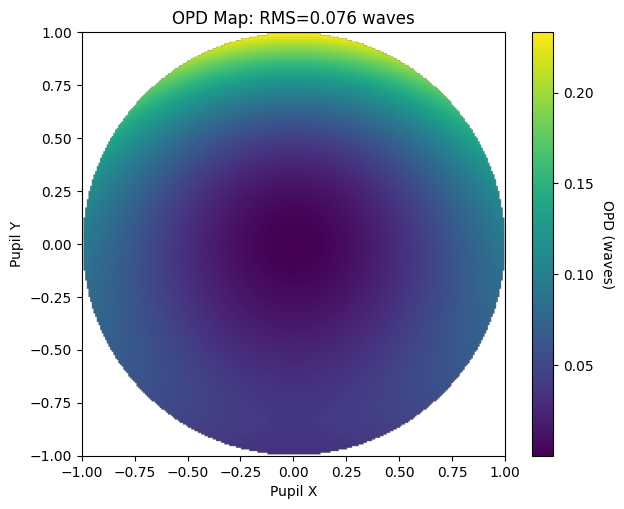

In [5]:
c = [0,0,0,0,0,0,0,0,0,0]
OPD(telescopeCreation(pdx=c[0], pdy=c[1], pdz=c[2], sdx=c[3], sdy=c[4], sdz=c[5]+200, ptx=c[6], pty=c[7], stx=c[8], sty=c[9]), field=(0, 0.5965), wavelength=0.65, num_rays=128).view()

In [6]:
import optiland.backend as be
from optiland import optic

K = 1000                    # µm → mm for piston / decenter
ARCSEC_TO_RAD = be.deg2rad(1 / 3600)

def telescopeCreation_absolute(
    WL=0.65,
    pdx=0, pdy=0, pdz=0, ptx=0, pty=0,
    sdx=0, sdy=0, sdz=0, stx=0, sty=0,
):
    # Nominal vertex z from thickness chain (mm)
    Z = [0.0]
    for t in (-7400.005, 7449.97, -1033.62, 1220.34):
        Z.append(Z[-1] + t)
    # Z = [0, -7400.005, 49.965, -983.655, 236.685]

    pearl = optic.Optic(name="Pearl")
    pearl.set_aperture(aperture_type="EPD", value=6471.26)
    pearl.wavelengths.add(value=WL)

    # Object — still uses thickness; field bias as object tilt
    pearl.surfaces.add(
        index=0,
        radius=be.inf,
        thickness=be.inf,
    )

    # --- absolute mode from here: x, y, z (no thickness, no dx/dy) ---

    pearl.surfaces.add(
        index=1,
        radius=-16256,
        x=pdx / K,
        y=pdy / K,
        z=0 + pdz / K,              # independent M1 piston
        rx=ptx * ARCSEC_TO_RAD,
        ry=pty * ARCSEC_TO_RAD,
        conic=-0.995357,
        material="mirror",
        is_stop=True,
    )
    pearl.surfaces.add(
        index=2,
        radius=-1660.575,
        x=sdx / K,
        y=sdy / K,
        z=-7400.005 + sdz / K,              # independent M2 piston
        rx=stx * ARCSEC_TO_RAD,
        ry=sty * ARCSEC_TO_RAD,
        conic=-1.566503,
        material="mirror",
    )
    pearl.surfaces.add(
        index=3,
        radius=-1830.5174,
        x=0.0, y=0.0, z=49.965,          # M3 fixed in lab frame
        conic=-0.718069,
        material="mirror",
    )
    pearl.surfaces.add(
        index=4,
        radius=be.inf,
        x=0.0, y=0.0, z=-983.655,          # M4 fixed
        material="mirror",
    )
    pearl.surfaces.add(
        index=5,
        x=0.0, y=0.0, z=236.685,          # image / detector
    )

    pearl.fields.set_type(field_type="angle")
    pearl.fields.add(y=0.17)
    pearl.fields.add(y=0.285)
    pearl.fields.add(y=0.055)

    return pearl

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.286 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

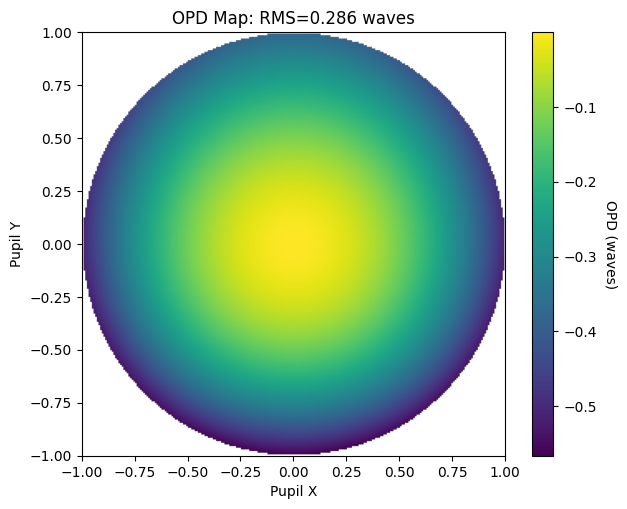

In [7]:
c = [0,0,0,0,0,0,0,0,0,0]
OPD(telescopeCreation_absolute(pdx=c[0], pdy=c[1], pdz=c[2]-2, sdx=c[3], sdy=c[4], sdz=c[5], ptx=c[6], pty=c[7], stx=c[8], sty=c[9]), field=(0, 0.5965), wavelength=0.65, num_rays=128).view()

In [8]:
def genpsf(WL=0.650, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field = (0,0)):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, num_rays=512)
    PSF = psf.psf[384:640,384:640]
    r = decompose_psf(PSF, nterms=dterms, basis=zernike_basis)

    return r

In [9]:
def genpsfn(WL=0.650, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field = (0,0)):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, num_rays=512)
    PSF = psf.psf[384:640,384:640]
    gauss_noise = np.random.normal(0, 0.01, PSF.shape)
    r = decompose_psf(PSF + gauss_noise, nterms=dterms, basis=zernike_basis)

    return r

In [66]:
xcy = []

for i in range(10000):
    px = np.round(np.random.normal(loc=0,scale=250), 2)
    py = np.round(np.random.normal(loc=0,scale=250), 2)
    pz = np.round(np.random.normal(loc=0,scale=50), 2)
    sx = np.round(np.random.normal(loc=0,scale=800), 2)
    sy = np.round(np.random.normal(loc=0,scale=800), 2)
    sz = np.round(np.random.normal(loc=0,scale=100), 2)
    ptx = np.round(np.random.normal(loc=0,scale=0.003), 2)
    pty = np.round(np.random.normal(loc=0,scale=0.003), 2)
    stx = np.round(np.random.normal(loc=0,scale=0.13), 2)
    sty = np.round(np.random.normal(loc=0,scale=0.13), 2)
    ars = genpsf(WL=0.65, pdx=px, pdy=py, pdz=pz, sdx=sx, sdy=sy, sdz=sz, ptx=ptx, pty=pty, stx=stx, sty=sty, dterms=11, field=(0,0))
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

In [134]:
xcy = np.array(xcy)

In [135]:
np.cov(xcy.T)

array([[ 9.13180778e-04, -1.41973881e-05,  2.79945029e-06,
        -5.90554049e-04, -2.36207031e-06, -1.79932806e-05,
         3.97197628e-06,  1.08299717e-05,  4.52515221e-06,
         2.96522882e-06,  2.98050389e-04],
       [-1.41973881e-05,  7.02079331e-04, -2.40210044e-06,
         1.12478197e-05,  4.05551471e-06,  3.33463917e-07,
         2.74260840e-06, -3.97072578e-04, -9.08437732e-07,
        -3.00919295e-06, -8.67272936e-06],
       [ 2.79945029e-06, -2.40210044e-06,  7.43778643e-04,
         6.55555332e-06, -5.84252200e-06, -4.83182626e-06,
        -4.26744931e-04,  1.51690026e-06, -7.38369565e-06,
        -1.95420396e-07, -8.33317070e-06],
       [-5.90554049e-04,  1.12478197e-05,  6.55555332e-06,
         4.88868227e-04,  1.97873560e-06,  9.43967314e-06,
        -1.11270648e-05, -1.34928721e-05, -2.82789626e-06,
        -9.64710325e-07, -2.90221030e-04],
       [-2.36207031e-06,  4.05551471e-06, -5.84252200e-06,
         1.97873560e-06,  2.32123282e-04, -2.26442152e-07,
  

In [10]:
#Truth

pdx_true = -152.75016400314658#truncnorm(-800, 800,loc=0,scale=250).rvs()
pdy_true =  316.9119521175452#truncnorm(-800, 800,loc=0,scale=250).rvs()
pdz_true =  26.63305492799793#truncnorm(-800, 800,loc=0,scale=50).rvs()
sdx_true =  -42.31026973120823#truncnorm(-2500, 2500,loc=0,scale=800).rvs()
sdy_true =  923.3301076415017#truncnorm(-2500, 2500,loc=0,scale=800).rvs()
sdz_true =  -32.7503419412196#truncnorm(-2500, 2500,loc=0,scale=100).rvs()
ptx_true =  2.9825886165449316e-05#truncnorm(-0.01, 0.01,loc=0,scale=0.003).rvs()
pty_true =  1.6083989287690292e-05#truncnorm(-0.01, 0.01,loc=0,scale=0.003).rvs()
stx_true =  0.02694973236912114#truncnorm(-0.4, 0.4,loc=0,scale=0.13).rvs()
sty_true =  0.009802980828159563#truncnorm(-0.4, 0.4,loc=0,scale=0.13).rvs()

## PSF
ct = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11)
ctf10 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(1,0))
ctf01 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(0,1))
ctf11 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(1,1))
ctfm10 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(-1,0))
ctf0m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(0,-1))
ctfm11 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(-1,1))
ctf1m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(1,-1))
ctfm1m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(-1,-1))
ctf05 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(0.5, 0.5))

print(f"{pdx_true},\n {pdy_true},\n {pdz_true},\n {sdx_true},\n {sdy_true}, \n {sdz_true}, \n {ptx_true},\n {pty_true},\n {stx_true},\n {sty_true}")

-152.75016400314658,
 316.9119521175452,
 26.63305492799793,
 -42.31026973120823,
 923.3301076415017, 
 -32.7503419412196, 
 2.9825886165449316e-05,
 1.6083989287690292e-05,
 0.02694973236912114,
 0.009802980828159563


In [15]:
from matplotlib_scalebar.scalebar import ScaleBar

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'MMDFT PSF'}, xlabel='X (µm)', ylabel='Y (µm)'>)

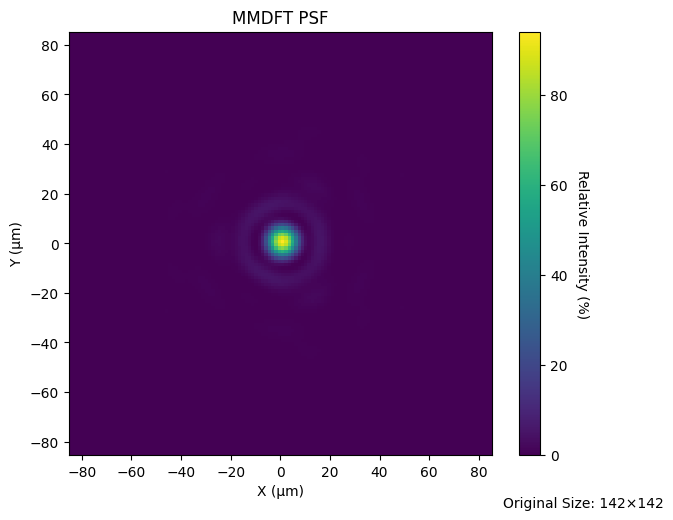

In [24]:
MMDFTPSF(telescopeCreation(pdx=c[0], pdy=c[1], pdz=0, sdx=c[3], sdy=c[4], sdz=2, ptx=c[6], pty=c[7], stx=c[8], sty=c[9]), wavelength=0.65, field=(0,0),num_rays=512).view()

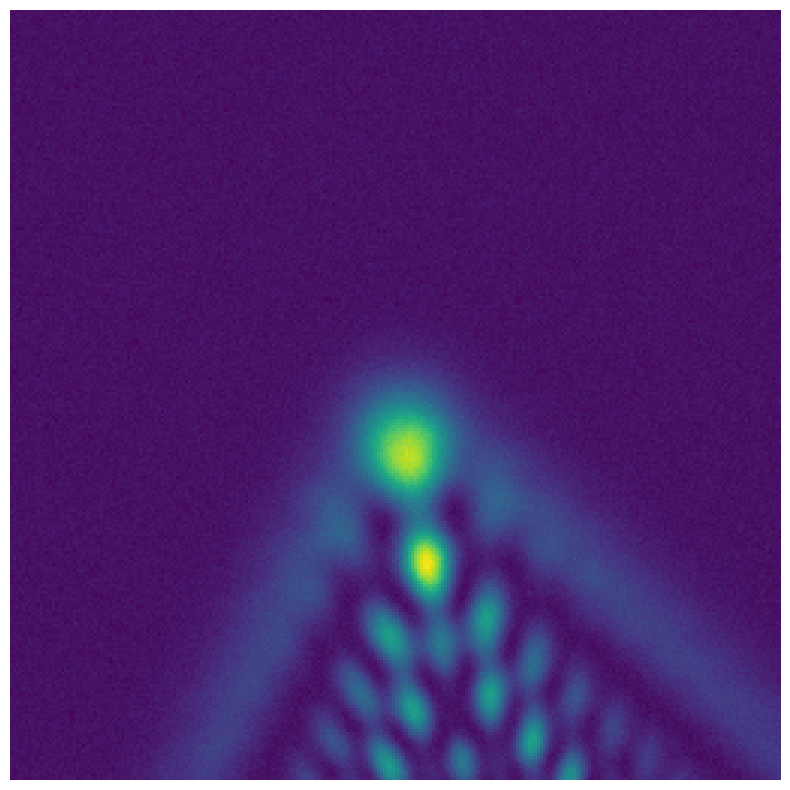

In [11]:
fig, ax = plt.subplots()
c = [pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true]
ax.imshow(MMDFTPSF(telescopeCreation(pdx=c[0], pdy=c[1], pdz=c[2], sdx=c[3], sdy=c[4], sdz=c[5], ptx=c[6], pty=c[7], stx=c[8], sty=c[9]), wavelength=0.65, field=(0,0),num_rays=512).psf[384:640,384:640] + np.random.normal(0, 0.01, (256,256)))
#scalebar = ScaleBar(1.2054001730168418, "um", length_fraction=0.4, location="upper left", font_properties={"size": 64})
#ax.add_artist(scalebar)
plt.axis("off")
plt.show()

In [12]:
C = np.array([[ 8.86762961e-04, -3.21885076e-06, -1.84073370e-05,
        -5.89731135e-04, -2.75108648e-06, -1.91421668e-07,
         2.07208311e-05,  8.00680471e-06, -5.78420178e-06,
         2.93123573e-06,  3.03390456e-04],
       [-3.21885076e-06,  7.14372650e-04,  1.44260537e-06,
         8.83524630e-06, -1.16203685e-05, -2.50592564e-06,
         1.37177132e-06, -4.07798614e-04,  1.56290060e-06,
        -8.08955919e-07, -1.02713125e-05],
       [-1.84073370e-05,  1.44260537e-06,  6.85837952e-04,
         1.69674041e-05, -2.60480353e-06, -7.47429305e-06,
        -3.90576811e-04,  2.00257355e-08,  4.71983575e-06,
         2.12515520e-06, -1.55859503e-05],
       [-5.89731135e-04,  8.83524630e-06,  1.69674041e-05,
         5.03994678e-04,  3.38548193e-06, -1.60224335e-06,
        -2.67642299e-05, -1.15172021e-05,  5.08906004e-06,
        -1.98934789e-06, -3.08594350e-04],
       [-2.75108648e-06, -1.16203685e-05, -2.60480353e-06,
         3.38548193e-06,  2.28594402e-04,  2.49695972e-07,
         1.17285388e-06,  1.12045193e-05,  1.56239406e-06,
         1.26038481e-07, -2.01195906e-06],
       [-1.91421668e-07, -2.50592564e-06, -7.47429305e-06,
        -1.60224335e-06,  2.49695972e-07,  2.25259767e-04,
         4.65035570e-06,  2.55823806e-06, -2.24061317e-08,
        -2.27187271e-06,  1.56023636e-06],
       [ 2.07208311e-05,  1.37177132e-06, -3.90576811e-04,
        -2.67642299e-05,  1.17285388e-06,  4.65035570e-06,
         2.81222394e-04, -2.59826857e-06, -1.34624286e-06,
        -2.32024915e-06,  2.16636567e-05],
       [ 8.00680471e-06, -4.07798614e-04,  2.00257355e-08,
        -1.15172021e-05,  1.12045193e-05,  2.55823806e-06,
        -2.59826857e-06,  2.94161586e-04, -1.49847796e-06,
        -1.35279387e-06,  1.29188255e-05],
       [-5.78420178e-06,  1.56290060e-06,  4.71983575e-06,
         5.08906004e-06,  1.56239406e-06, -2.24061317e-08,
        -1.34624286e-06, -1.49847796e-06,  5.66867844e-05,
        -1.32942469e-06, -3.40020348e-06],
       [ 2.93123573e-06, -8.08955919e-07,  2.12515520e-06,
        -1.98934789e-06,  1.26038481e-07, -2.27187271e-06,
        -2.32024915e-06, -1.35279387e-06, -1.32942469e-06,
         6.65306187e-05,  7.33260741e-08],
       [ 3.03390456e-04, -1.02713125e-05, -1.55859503e-05,
        -3.08594350e-04, -2.01195906e-06,  1.56023636e-06,
         2.16636567e-05,  1.29188255e-05, -3.40020348e-06,
         7.33260741e-08,  2.30601029e-04]])

Cf10 = np.array([[ 9.32853986e-04,  1.18858507e-05,  6.46715068e-06,
        -6.35787815e-04,  4.45557775e-06,  1.42693656e-05,
        -6.00940160e-06, -9.77698597e-06,  1.07321640e-06,
         4.91594454e-06,  3.39624224e-04],
       [ 1.18858507e-05,  7.26589922e-04,  1.05686016e-05,
        -7.90977354e-06, -1.02013667e-06,  1.31195298e-05,
        -6.41813900e-06, -4.31265324e-04,  4.76606189e-06,
        -3.10880434e-06,  1.27152543e-06],
       [ 6.46715068e-06,  1.05686016e-05,  7.07372405e-04,
        -2.28100258e-06, -1.18104070e-05, -3.23021226e-06,
        -4.04809729e-04, -7.06787521e-06,  2.94376898e-07,
         5.27601215e-07, -8.07988771e-07],
       [-6.35787815e-04, -7.90977354e-06, -2.28100258e-06,
         5.65032635e-04, -1.94587748e-06, -1.44408593e-05,
         1.14908568e-06,  8.42142238e-06, -4.85273849e-07,
        -7.09206156e-06, -3.55722342e-04],
       [ 4.45557775e-06, -1.02013667e-06, -1.18104070e-05,
        -1.94587748e-06,  2.32305659e-04,  4.30758685e-06,
         7.98637379e-06,  2.03219874e-06,  1.49209353e-06,
         1.33977736e-06,  7.35264973e-07],
       [ 1.42693656e-05,  1.31195298e-05, -3.23021226e-06,
        -1.44408593e-05,  4.30758685e-06,  2.33729765e-04,
         3.34641098e-06, -1.03319385e-05,  7.59767524e-07,
        -1.75651919e-06,  7.51315876e-06],
       [-6.00940160e-06, -6.41813900e-06, -4.04809729e-04,
         1.14908568e-06,  7.98637379e-06,  3.34641098e-06,
         2.94592546e-04,  4.36092400e-06, -2.13768580e-06,
        -5.33576638e-07,  2.84554541e-06],
       [-9.77698597e-06, -4.31265324e-04, -7.06787521e-06,
         8.42142238e-06,  2.03219874e-06, -1.03319385e-05,
         4.36092400e-06,  3.22172274e-04, -2.80577956e-06,
        -3.39297396e-07, -3.70649846e-06],
       [ 1.07321640e-06,  4.76606189e-06,  2.94376898e-07,
        -4.85273849e-07,  1.49209353e-06,  7.59767524e-07,
        -2.13768580e-06, -2.80577956e-06,  5.79797830e-05,
        -2.06228439e-06,  2.39250176e-07],
       [ 4.91594454e-06, -3.10880434e-06,  5.27601215e-07,
        -7.09206156e-06,  1.33977736e-06, -1.75651919e-06,
        -5.33576638e-07, -3.39297396e-07, -2.06228439e-06,
         7.00988670e-05,  3.77928710e-06],
       [ 3.39624224e-04,  1.27152543e-06, -8.07988771e-07,
        -3.55722342e-04,  7.35264973e-07,  7.51315876e-06,
         2.84554541e-06, -3.70649846e-06,  2.39250176e-07,
         3.77928710e-06,  2.67967548e-04]])

Cf01 = np.array([[ 8.87791856e-04, -2.55900061e-06,  2.42651632e-07,
        -5.93744226e-04,  2.07793843e-06,  1.56690683e-06,
        -3.40099944e-07, -3.46520861e-06,  4.02052692e-06,
        -4.16496688e-06,  3.14591839e-04],
       [-2.55900061e-06,  7.00169442e-04,  5.68630015e-06,
        -7.68465133e-06,  1.23784692e-05, -9.56838946e-06,
        -2.18992079e-06, -3.95048052e-04,  9.61388814e-07,
         5.92811130e-06,  6.33594537e-06],
       [ 2.42651632e-07,  5.68630015e-06,  6.95780308e-04,
         8.61539644e-06, -7.17757855e-07,  1.14845935e-06,
        -3.97879000e-04, -2.41990648e-07,  5.47893971e-07,
        -9.54843832e-07, -4.97620279e-06],
       [-5.93744226e-04, -7.68465133e-06,  8.61539644e-06,
         5.24958907e-04,  2.23010104e-06,  9.43306040e-07,
        -1.14455449e-06,  7.40937003e-06, -1.54930533e-06,
         2.00146739e-06, -3.30520504e-04],
       [ 2.07793843e-06,  1.23784692e-05, -7.17757855e-07,
         2.23010104e-06,  2.22099558e-04,  1.01506219e-06,
        -4.14490058e-06, -5.05472132e-06, -3.47759654e-06,
        -1.21227421e-07, -3.80413148e-06],
       [ 1.56690683e-06, -9.56838946e-06,  1.14845935e-06,
         9.43306040e-07,  1.01506219e-06,  2.32733845e-04,
        -4.25373258e-06,  6.89372872e-06,  5.99465681e-06,
        -1.16992211e-06, -2.17803083e-06],
       [-3.40099944e-07, -2.18992079e-06, -3.97879000e-04,
        -1.14455449e-06, -4.14490058e-06, -4.25373258e-06,
         2.91568960e-04, -3.85224794e-06, -6.94558886e-07,
         1.29769461e-06, -2.40576111e-06],
       [-3.46520861e-06, -3.95048052e-04, -2.41990648e-07,
         7.40937003e-06, -5.05472132e-06,  6.89372872e-06,
        -3.85224794e-06,  2.81272100e-04, -1.28009527e-06,
        -2.92863943e-06, -5.05878225e-06],
       [ 4.02052692e-06,  9.61388814e-07,  5.47893971e-07,
        -1.54930533e-06, -3.47759654e-06,  5.99465681e-06,
        -6.94558886e-07, -1.28009527e-06,  5.59732715e-05,
         1.19892762e-06, -4.95259897e-08],
       [-4.16496688e-06,  5.92811130e-06, -9.54843832e-07,
         2.00146739e-06, -1.21227421e-07, -1.16992211e-06,
         1.29769461e-06, -2.92863943e-06,  1.19892762e-06,
         6.84596246e-05,  2.71223451e-07],
       [ 3.14591839e-04,  6.33594537e-06, -4.97620279e-06,
        -3.30520504e-04, -3.80413148e-06, -2.17803083e-06,
        -2.40576111e-06, -5.05878225e-06, -4.95259897e-08,
         2.71223451e-07,  2.52783809e-04]])

Cf11 = np.array([[ 9.19794418e-04,  1.63348531e-05,  1.81700881e-05,
        -5.90086379e-04,  1.27913839e-05, -8.90417445e-06,
        -2.56319807e-05, -1.78388859e-05,  8.99921488e-06,
        -2.30536582e-06,  2.91038260e-04],
       [ 1.63348531e-05,  7.11931114e-04,  2.12709626e-05,
        -7.34918768e-06,  1.00509131e-05,  2.77503009e-06,
        -1.34172064e-05, -4.07676143e-04,  1.79909737e-06,
        -7.40789295e-06, -1.30913706e-06],
       [ 1.81700881e-05,  2.12709626e-05,  7.26000280e-04,
        -1.56337196e-05,  1.83983239e-05,  7.31685865e-07,
        -4.19958214e-04, -1.22651725e-05, -2.35686895e-06,
        -7.16051138e-06,  1.02308252e-05],
       [-5.90086379e-04, -7.34918768e-06, -1.56337196e-05,
         4.96476284e-04, -6.81396836e-06,  5.51958240e-06,
         2.91066612e-05,  5.18267856e-06, -7.21454136e-06,
        -2.40291579e-06, -2.98668905e-04],
       [ 1.27913839e-05,  1.00509131e-05,  1.83983239e-05,
        -6.81396836e-06,  2.32286004e-04, -3.70553324e-06,
        -9.25730167e-06, -7.57836212e-06,  5.11837080e-06,
        -2.38341984e-06,  2.58159941e-06],
       [-8.90417445e-06,  2.77503009e-06,  7.31685865e-07,
         5.51958240e-06, -3.70553324e-06,  2.40560440e-04,
        -2.41542788e-06, -2.58696466e-06,  1.39869741e-06,
         4.20866618e-06, -2.24760758e-06],
       [-2.56319807e-05, -1.34172064e-05, -4.19958214e-04,
         2.91066612e-05, -9.25730167e-06, -2.41542788e-06,
         3.07889954e-04,  5.97785762e-06,  1.87295918e-06,
         3.53673895e-06, -2.23736397e-05],
       [-1.78388859e-05, -4.07676143e-04, -1.22651725e-05,
         5.18267856e-06, -7.57836212e-06, -2.58696466e-06,
         5.97785762e-06,  2.91196013e-04,  1.62039242e-07,
         7.68428405e-06,  3.92511213e-06],
       [ 8.99921488e-06,  1.79909737e-06, -2.35686895e-06,
        -7.21454136e-06,  5.11837080e-06,  1.39869741e-06,
         1.87295918e-06,  1.62039242e-07,  5.96193446e-05,
        -1.37797870e-06,  4.15015776e-06],
       [-2.30536582e-06, -7.40789295e-06, -7.16051138e-06,
        -2.40291579e-06, -2.38341984e-06,  4.20866618e-06,
         3.53673895e-06,  7.68428405e-06, -1.37797870e-06,
         6.93676271e-05,  3.04916290e-06],
       [ 2.91038260e-04, -1.30913706e-06,  1.02308252e-05,
        -2.98668905e-04,  2.58159941e-06, -2.24760758e-06,
        -2.23736397e-05,  3.92511213e-06,  4.15015776e-06,
         3.04916290e-06,  2.22407715e-04]])

Cfm10 = np.array([[ 9.41867796e-04,  5.02474554e-06, -2.22509424e-05,
        -6.19131433e-04,  2.00554320e-06,  8.71170636e-06,
         1.35644962e-05, -7.36191732e-06,  2.15145797e-06,
         2.28867434e-06,  3.10043857e-04],
       [ 5.02474554e-06,  7.50485389e-04,  1.42053248e-05,
        -8.75403362e-07, -3.91580202e-06,  6.19649408e-06,
        -4.59579159e-06, -4.40943013e-04,  1.22701344e-06,
         2.65644111e-06,  1.78448935e-07],
       [-2.22509424e-05,  1.42053248e-05,  7.01669071e-04,
         1.63511066e-05, -2.43060120e-06,  7.53131163e-06,
        -3.99760924e-04, -4.34328784e-06,  6.73515243e-06,
        -1.65269802e-06, -7.64582361e-06],
       [-6.19131433e-04, -8.75403362e-07,  1.63511066e-05,
         5.12886338e-04,  3.92791123e-06, -1.06405277e-05,
        -7.29588998e-06,  4.86631495e-06, -2.24245534e-06,
        -2.69699430e-06, -2.97152937e-04],
       [ 2.00554320e-06, -3.91580202e-06, -2.43060120e-06,
         3.92791123e-06,  2.38029606e-04,  1.00861063e-06,
         2.47932097e-06,  2.80035891e-06,  8.35314983e-07,
        -2.61178652e-06, -3.44794738e-06],
       [ 8.71170636e-06,  6.19649408e-06,  7.53131163e-06,
        -1.06405277e-05,  1.00861063e-06,  2.34580982e-04,
        -9.01437373e-06, -3.44036774e-06, -2.81934062e-06,
        -3.19425928e-07,  7.93491467e-06],
       [ 1.35644962e-05, -4.59579159e-06, -3.99760924e-04,
        -7.29588998e-06,  2.47932097e-06, -9.01437373e-06,
         2.86090216e-04, -7.27127763e-07, -3.68108285e-06,
        -2.09393296e-06,  3.42568387e-06],
       [-7.36191732e-06, -4.40943013e-04, -4.34328784e-06,
         4.86631495e-06,  2.80035891e-06, -3.44036774e-06,
        -7.27127763e-07,  3.30000310e-04,  1.44283360e-07,
        -2.27765849e-06, -2.44151056e-06],
       [ 2.15145797e-06,  1.22701344e-06,  6.73515243e-06,
        -2.24245534e-06,  8.35314983e-07, -2.81934062e-06,
        -3.68108285e-06,  1.44283360e-07,  6.14372383e-05,
         8.61776473e-07,  1.37990845e-06],
       [ 2.28867434e-06,  2.65644111e-06, -1.65269802e-06,
        -2.69699430e-06, -2.61178652e-06, -3.19425928e-07,
        -2.09393296e-06, -2.27765849e-06,  8.61776473e-07,
         7.01172963e-05,  3.21423802e-06],
       [ 3.10043857e-04,  1.78448935e-07, -7.64582361e-06,
        -2.97152937e-04, -3.44794738e-06,  7.93491467e-06,
         3.42568387e-06, -2.44151056e-06,  1.37990845e-06,
         3.21423802e-06,  2.03982595e-04]])

Cf0m1 = np.array([[ 9.19217735e-04,  4.16838859e-06,  5.17843873e-06,
        -6.06224226e-04, -8.26399227e-06,  9.95258376e-07,
        -7.98935492e-06, -1.02719567e-05, -4.45989770e-06,
        -3.08531988e-06,  3.13179463e-04],
       [ 4.16838859e-06,  7.17192418e-04,  4.78276448e-07,
        -7.79682008e-06, -6.99436974e-06, -3.66334097e-06,
         2.43250363e-06, -4.17087903e-04, -2.43438323e-06,
        -5.22852412e-06,  5.06908353e-06],
       [ 5.17843873e-06,  4.78276448e-07,  7.16596896e-04,
        -5.15249118e-06,  4.97486764e-06, -8.58397902e-06,
        -4.06559803e-04,  2.65841671e-07, -7.27720355e-07,
         4.31372861e-06,  5.73848535e-06],
       [-6.06224226e-04, -7.79682008e-06, -5.15249118e-06,
         5.22317763e-04,  6.01645692e-06, -5.63617703e-06,
         1.48922140e-05,  1.53143266e-05,  2.93967889e-06,
         2.34610168e-06, -3.21338815e-04],
       [-8.26399227e-06, -6.99436974e-06,  4.97486764e-06,
         6.01645692e-06,  2.32966173e-04, -1.03270219e-06,
        -4.65543892e-06,  5.85906038e-06, -4.48419018e-07,
        -8.85672260e-07, -2.97686106e-06],
       [ 9.95258376e-07, -3.66334097e-06, -8.58397902e-06,
        -5.63617703e-06, -1.03270219e-06,  2.34898749e-04,
         6.45839297e-06,  3.09031314e-06, -1.12251412e-06,
         2.15772193e-06,  3.65576335e-06],
       [-7.98935492e-06,  2.43250363e-06, -4.06559803e-04,
         1.48922140e-05, -4.65543892e-06,  6.45839297e-06,
         2.88824636e-04, -6.87703353e-07, -1.23677903e-06,
        -2.71460382e-06, -1.47308004e-05],
       [-1.02719567e-05, -4.17087903e-04,  2.65841671e-07,
         1.53143266e-05,  5.85906038e-06,  3.09031314e-06,
        -6.87703353e-07,  3.07005565e-04,  1.10127881e-06,
         2.15759095e-06, -1.40741455e-05],
       [-4.45989770e-06, -2.43438323e-06, -7.27720355e-07,
         2.93967889e-06, -4.48419018e-07, -1.12251412e-06,
        -1.23677903e-06,  1.10127881e-06,  5.79524188e-05,
         1.56582349e-07, -1.66926051e-06],
       [-3.08531988e-06, -5.22852412e-06,  4.31372861e-06,
         2.34610168e-06, -8.85672260e-07,  2.15772193e-06,
        -2.71460382e-06,  2.15759095e-06,  1.56582349e-07,
         7.33296041e-05, -7.28207447e-07],
       [ 3.13179463e-04,  5.06908353e-06,  5.73848535e-06,
        -3.21338815e-04, -2.97686106e-06,  3.65576335e-06,
        -1.47308004e-05, -1.40741455e-05, -1.66926051e-06,
        -7.28207447e-07,  2.39858043e-04]])

Cfm11 = np.array([[ 9.33571929e-04, -9.84483566e-06, -5.80883595e-06,
        -6.12774826e-04, -2.02528242e-06,  1.05327860e-05,
        -2.58842274e-06, -6.65792386e-07,  5.28952915e-09,
        -9.11110799e-06,  3.11778030e-04],
       [-9.84483566e-06,  7.29725395e-04, -1.13529964e-05,
         5.33414617e-06,  1.20146723e-06, -4.57174551e-06,
         9.13844284e-06, -4.25925158e-04, -1.80156835e-06,
         2.86797035e-06, -2.77281675e-06],
       [-5.80883595e-06, -1.13529964e-05,  7.10954440e-04,
        -1.20654242e-06,  4.73550145e-06,  5.98819460e-06,
        -4.10123323e-04,  8.27789610e-06,  6.85554748e-06,
        -1.50658181e-06, -4.46805526e-07],
       [-6.12774826e-04,  5.33414617e-06, -1.20654242e-06,
         5.25093138e-04,  1.23110523e-06, -7.90685873e-06,
         5.99079313e-06,  5.79954149e-06,  1.38788551e-06,
         4.25477668e-06, -3.18420788e-04],
       [-2.02528242e-06,  1.20146723e-06,  4.73550145e-06,
         1.23110523e-06,  2.29809064e-04, -3.11209737e-06,
        -1.77418529e-06,  1.37087849e-06, -4.07639940e-07,
        -2.23227454e-06, -3.08037584e-07],
       [ 1.05327860e-05, -4.57174551e-06,  5.98819460e-06,
        -7.90685873e-06, -3.11209737e-06,  2.28458472e-04,
        -2.26965157e-06,  4.02874837e-06, -3.18233174e-06,
         2.36749919e-06,  1.85526195e-06],
       [-2.58842274e-06,  9.13844284e-06, -4.10123323e-04,
         5.99079313e-06, -1.77418529e-06, -2.26965157e-06,
         3.00157238e-04, -7.15122221e-06, -6.15712307e-06,
         1.65053297e-06, -2.84305063e-06],
       [-6.65792386e-07, -4.25925158e-04,  8.27789610e-06,
         5.79954149e-06,  1.37087849e-06,  4.02874837e-06,
        -7.15122221e-06,  3.11918609e-04,  1.93298121e-06,
        -2.28201556e-06, -6.57265036e-06],
       [ 5.28952915e-09, -1.80156835e-06,  6.85554748e-06,
         1.38788551e-06, -4.07639940e-07, -3.18233174e-06,
        -6.15712307e-06,  1.93298121e-06,  5.65744216e-05,
        -1.05802263e-06, -1.33812910e-06],
       [-9.11110799e-06,  2.86797035e-06, -1.50658181e-06,
         4.25477668e-06, -2.23227454e-06,  2.36749919e-06,
         1.65053297e-06, -2.28201556e-06, -1.05802263e-06,
         7.05865819e-05, -3.17014264e-06],
       [ 3.11778030e-04, -2.77281675e-06, -4.46805526e-07,
        -3.18420788e-04, -3.08037584e-07,  1.85526195e-06,
        -2.84305063e-06, -6.57265036e-06, -1.33812910e-06,
        -3.17014264e-06,  2.35007541e-04]])

Cf1m1 = np.array([[ 8.57451479e-04, -3.23497274e-05,  8.99276423e-06,
        -5.41006207e-04, -1.66953639e-06,  1.14468109e-05,
        -1.54663942e-05,  2.96988917e-05, -6.98043831e-07,
        -5.75620653e-07,  2.71710710e-04],
       [-3.23497274e-05,  7.30862126e-04,  5.90954986e-06,
         2.74305488e-05,  3.99060960e-06, -1.41539741e-06,
        -3.57307708e-06, -4.08643421e-04, -4.75763021e-06,
         3.68300214e-06, -1.89111155e-05],
       [ 8.99276423e-06,  5.90954986e-06,  6.89279383e-04,
        -5.90354876e-06, -6.31229584e-06, -7.34771932e-06,
        -3.85234534e-04, -2.62022290e-06,  3.89038964e-06,
        -3.21029268e-06,  2.42404463e-06],
       [-5.41006207e-04,  2.74305488e-05, -5.90354876e-06,
         4.43136267e-04,  4.93214361e-07, -5.53929649e-06,
         1.42602986e-05, -2.93742871e-05, -6.25382119e-07,
         2.71642208e-06, -2.63481807e-04],
       [-1.66953639e-06,  3.99060960e-06, -6.31229584e-06,
         4.93214361e-07,  2.28484201e-04, -5.59653859e-06,
         5.18566437e-06, -7.01703177e-06, -2.57729463e-06,
         4.69404109e-07,  4.59319675e-07],
       [ 1.14468109e-05, -1.41539741e-06, -7.34771932e-06,
        -5.53929649e-06, -5.59653859e-06,  2.31960516e-04,
         3.13587790e-06,  4.14131262e-06,  3.94668132e-06,
         2.64239980e-06,  2.39357137e-06],
       [-1.54663942e-05, -3.57307708e-06, -3.85234534e-04,
         1.42602986e-05,  5.18566437e-06,  3.13587790e-06,
         2.69410493e-04,  1.61492819e-06, -3.46031756e-06,
         2.47137804e-06, -7.75333431e-06],
       [ 2.96988917e-05, -4.08643421e-04, -2.62022290e-06,
        -2.93742871e-05, -7.01703177e-06,  4.14131262e-06,
         1.61492819e-06,  2.85222618e-04,  2.96935210e-06,
        -2.90921308e-06,  2.06666696e-05],
       [-6.98043831e-07, -4.75763021e-06,  3.89038964e-06,
        -6.25382119e-07, -2.57729463e-06,  3.94668132e-06,
        -3.46031756e-06,  2.96935210e-06,  5.67122760e-05,
        -4.94215030e-07,  5.87635715e-07],
       [-5.75620653e-07,  3.68300214e-06, -3.21029268e-06,
         2.71642208e-06,  4.69404109e-07,  2.64239980e-06,
         2.47137804e-06, -2.90921308e-06, -4.94215030e-07,
         6.90318917e-05, -3.79481463e-06],
       [ 2.71710710e-04, -1.89111155e-05,  2.42404463e-06,
        -2.63481807e-04,  4.59319675e-07,  2.39357137e-06,
        -7.75333431e-06,  2.06666696e-05,  5.87635715e-07,
        -3.79481463e-06,  1.88798698e-04]])

Cfm1m1 = np.array([[ 9.16272208e-04, -6.72407375e-06,  2.12008576e-06,
        -5.99549690e-04, -3.75151852e-06, -3.67504186e-06,
        -4.39901423e-06,  1.29953233e-05,  4.01510163e-06,
         6.90315740e-06,  3.05523037e-04],
       [-6.72407375e-06,  7.05761409e-04, -2.38382749e-06,
         9.51150491e-06,  6.49564965e-06,  6.32834740e-06,
         2.83729573e-06, -4.02183599e-04, -2.52113622e-06,
        -1.08075500e-06, -6.29944357e-06],
       [ 2.12008576e-06, -2.38382749e-06,  7.13421884e-04,
         1.39086812e-06, -8.45757025e-06, -3.05097013e-06,
        -4.04036491e-04,  2.26622641e-06, -2.35342266e-06,
         8.40812562e-07, -1.57135302e-06],
       [-5.99549690e-04,  9.51150491e-06,  1.39086812e-06,
         5.12409986e-04,  4.69267895e-06,  1.92350093e-06,
         2.94243940e-06, -1.53367590e-05, -2.41275087e-06,
        -3.78033104e-06, -3.16652193e-04],
       [-3.75151852e-06,  6.49564965e-06, -8.45757025e-06,
         4.69267895e-06,  2.31116635e-04, -8.78069445e-07,
         4.11478933e-06, -4.91819414e-07, -7.09090070e-07,
        -2.00172956e-06, -2.09432821e-06],
       [-3.67504186e-06,  6.32834740e-06, -3.05097013e-06,
         1.92350093e-06, -8.78069445e-07,  2.33361660e-04,
         1.13830404e-06, -6.28566244e-07, -4.27435113e-07,
         2.75624205e-06, -9.60576326e-07],
       [-4.39901423e-06,  2.83729573e-06, -4.04036491e-04,
         2.94243940e-06,  4.11478933e-06,  1.13830404e-06,
         2.89042948e-04, -1.10528079e-06,  1.67172405e-06,
        -8.59754465e-08, -9.34866629e-07],
       [ 1.29953233e-05, -4.02183599e-04,  2.26622641e-06,
        -1.53367590e-05, -4.91819414e-07, -6.28566244e-07,
        -1.10528079e-06,  2.92897724e-04,  9.01930731e-07,
        -1.68683598e-07,  1.15295395e-05],
       [ 4.01510163e-06, -2.52113622e-06, -2.35342266e-06,
        -2.41275087e-06, -7.09090070e-07, -4.27435113e-07,
         1.67172405e-06,  9.01930731e-07,  5.80541504e-05,
         7.17274245e-07,  1.61961470e-06],
       [ 6.90315740e-06, -1.08075500e-06,  8.40812562e-07,
        -3.78033104e-06, -2.00172956e-06,  2.75624205e-06,
        -8.59754465e-08, -1.68683598e-07,  7.17274245e-07,
         7.27830557e-05,  5.94171037e-07],
       [ 3.05523037e-04, -6.29944357e-06, -1.57135302e-06,
        -3.16652193e-04, -2.09432821e-06, -9.60576326e-07,
        -9.34866629e-07,  1.15295395e-05,  1.61961470e-06,
         5.94171037e-07,  2.40287485e-04]])

Cf05 = np.array([[ 9.13180778e-04, -1.41973881e-05,  2.79945029e-06,
        -5.90554049e-04, -2.36207031e-06, -1.79932806e-05,
         3.97197628e-06,  1.08299717e-05,  4.52515221e-06,
         2.96522882e-06,  2.98050389e-04],
       [-1.41973881e-05,  7.02079331e-04, -2.40210044e-06,
         1.12478197e-05,  4.05551471e-06,  3.33463917e-07,
         2.74260840e-06, -3.97072578e-04, -9.08437732e-07,
        -3.00919295e-06, -8.67272936e-06],
       [ 2.79945029e-06, -2.40210044e-06,  7.43778643e-04,
         6.55555332e-06, -5.84252200e-06, -4.83182626e-06,
        -4.26744931e-04,  1.51690026e-06, -7.38369565e-06,
        -1.95420396e-07, -8.33317070e-06],
       [-5.90554049e-04,  1.12478197e-05,  6.55555332e-06,
         4.88868227e-04,  1.97873560e-06,  9.43967314e-06,
        -1.11270648e-05, -1.34928721e-05, -2.82789626e-06,
        -9.64710325e-07, -2.90221030e-04],
       [-2.36207031e-06,  4.05551471e-06, -5.84252200e-06,
         1.97873560e-06,  2.32123282e-04, -2.26442152e-07,
         3.25772476e-06,  1.67723036e-06,  1.67521823e-06,
        -3.47290524e-07, -2.38304381e-06],
       [-1.79932806e-05,  3.33463917e-07, -4.83182626e-06,
         9.43967314e-06, -2.26442152e-07,  2.44950152e-04,
         1.10035226e-06,  1.99008440e-06,  5.10361201e-06,
        -1.35917459e-06, -3.65030830e-06],
       [ 3.97197628e-06,  2.74260840e-06, -4.26744931e-04,
        -1.11270648e-05,  3.25772476e-06,  1.10035226e-06,
         3.09126152e-04, -3.61670869e-06,  5.00704115e-06,
         1.35510624e-06,  1.26323720e-05],
       [ 1.08299717e-05, -3.97072578e-04,  1.51690026e-06,
        -1.34928721e-05,  1.67723036e-06,  1.99008440e-06,
        -3.61670869e-06,  2.83562789e-04,  1.47363067e-06,
         3.43442745e-06,  1.45222530e-05],
       [ 4.52515221e-06, -9.08437732e-07, -7.38369565e-06,
        -2.82789626e-06,  1.67521823e-06,  5.10361201e-06,
         5.00704115e-06,  1.47363067e-06,  5.96287245e-05,
         2.55897591e-07,  1.64229853e-06],
       [ 2.96522882e-06, -3.00919295e-06, -1.95420396e-07,
        -9.64710325e-07, -3.47290524e-07, -1.35917459e-06,
         1.35510624e-06,  3.43442745e-06,  2.55897591e-07,
         7.12413868e-05,  1.41093383e-06],
       [ 2.98050389e-04, -8.67272936e-06, -8.33317070e-06,
        -2.90221030e-04, -2.38304381e-06, -3.65030830e-06,
         1.26323720e-05,  1.45222530e-05,  1.64229853e-06,
         1.41093383e-06,  2.08421412e-04]])


Cinv =    np.linalg.inv(C)  # precision matrix
Cf10inv = np.linalg.inv(Cf10)
Cf01inv = np.linalg.inv(Cf01)
Cf11inv = np.linalg.inv(Cf11)
Cfm10inv = np.linalg.inv(Cfm10)
Cf0m1inv = np.linalg.inv(Cf0m1)
Cfm11inv = np.linalg.inv(Cfm11)
Cf1m1inv = np.linalg.inv(Cf1m1)
Cfm1m1inv = np.linalg.inv(Cfm1m1)
Cf05inv = np.linalg.inv(Cf05)
lnorm =    -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(C)))  # ln(normalization)
lnormf10 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf10))) 
lnormf01 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf01))) 
lnormf11 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf11))) 
lnormfm10 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cfm10))) 
lnormf0m1 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf0m1))) 
lnormfm11 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cfm11)))
lnormf1m1 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf1m1)))
lnormfm1m1 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cfm1m1)))
lnormf05 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf05)))

# log-likelihood
def loglike(theta):
    lpdx,lpdy,lpdz,lsdx,lsdy,lsdz,lptx,lpty,lstx,lsty = theta
    ## PSF
    c = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11)
    cf10 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(1,0))
    cf01 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(0,1))
    cf11 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(1,1))
    cfm10 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(-1,0))
    cf0m1 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(0,-1))
    cfm11 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(-1,1))
    cf1m1 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(1,-1))
    cfm1m1 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(-1,-1))
    cf05 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(0.5,0.5))
    
    return -0.5 * np.matmul(c-ct, np.matmul(Cinv, c-ct)) + lnorm -0.5 * np.matmul(cf10-ctf10, np.matmul(Cf10inv, cf10-ctf10)) + lnormf10 -0.5 * np.matmul(cf01-ctf01, np.matmul(Cf01inv, cf01-ctf01)) + lnormf01 -0.5 * np.matmul(cf11-ctf11, np.matmul(Cf11inv, cf11-ctf11)) + lnormf11 -0.5 * np.matmul(cfm10-ctfm10, np.matmul(Cfm10inv, cfm10-ctfm10)) + lnormfm10 -0.5 * np.matmul(cf0m1-ctf0m1, np.matmul(Cf0m1inv, cf0m1-ctf0m1)) + lnormf0m1 -0.5 * np.matmul(cfm11-ctfm11, np.matmul(Cfm11inv, cfm11-ctfm11)) + lnormfm11 -0.5 * np.matmul(cf1m1-ctf1m1, np.matmul(Cf1m1inv, cf1m1-ctf1m1)) + lnormf1m1 -0.5 * np.matmul(cfm1m1-ctfm1m1, np.matmul(Cfm1m1inv, cfm1m1-ctfm1m1)) + lnormfm1m1 -0.5 * np.matmul(cf05-ctf05, np.matmul(Cf05inv, cf05-ctf05)) + lnormf05

# prior transform
def ptform(utheta):

    upx,upy,upz,usx,usy,usz,uptx,upty,ustx,usty = utheta

    xpx =  800. * (2. * upx - 1.)
    xpy =  800. * (2. * upy - 1.)
    xpz =  800. * (2. * upz - 1.)
    xsx =  2500. * (2. * usx - 1.)
    xsy =  2500. * (2. * usy - 1.)
    xsz =  2500. * (2. * usz - 1.)
    tpx =  0.01 * (2. * uptx - 1.)
    tpy =  0.01 * (2. * upty - 1.)
    tsx =  0.4 * (2. * ustx - 1.)
    tsy =  0.4 * (2. * usty - 1.)

    return xpx,xpy,xpz,xsx,xsy,xsz,tpx,tpy,tsx,tsy

In [13]:
loglike([pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true])

np.float64(391.4131857654545)

In [13]:
lnorm + lnormf10 + lnormf01 + lnormf11 + lnormfm10 + lnormf0m1 + lnormfm11 + lnormf1m1 + lnormfm1m1 + lnormf05

np.float64(391.4146403413526)

In [12]:
print([pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true])

[-152.75016400314658, 316.9119521175452, 26.63305492799793, -42.31026973120823, 923.3301076415017, -32.7503419412196, 2.9825886165449316e-05, 1.6083989287690292e-05, 0.02694973236912114, 0.009802980828159563]


In [ ]:
sampler = Sampler(ptform, loglike, n_dim=10)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    


KeyboardInterrupt: 

Process ForkPoolWorker-52:
Process ForkPoolWorker-51:
Process ForkPoolWorker-53:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/multiprocess/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/multiprocess/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/multiprocess/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/multiprocess/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/multiprocess/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/multiprocess/pr

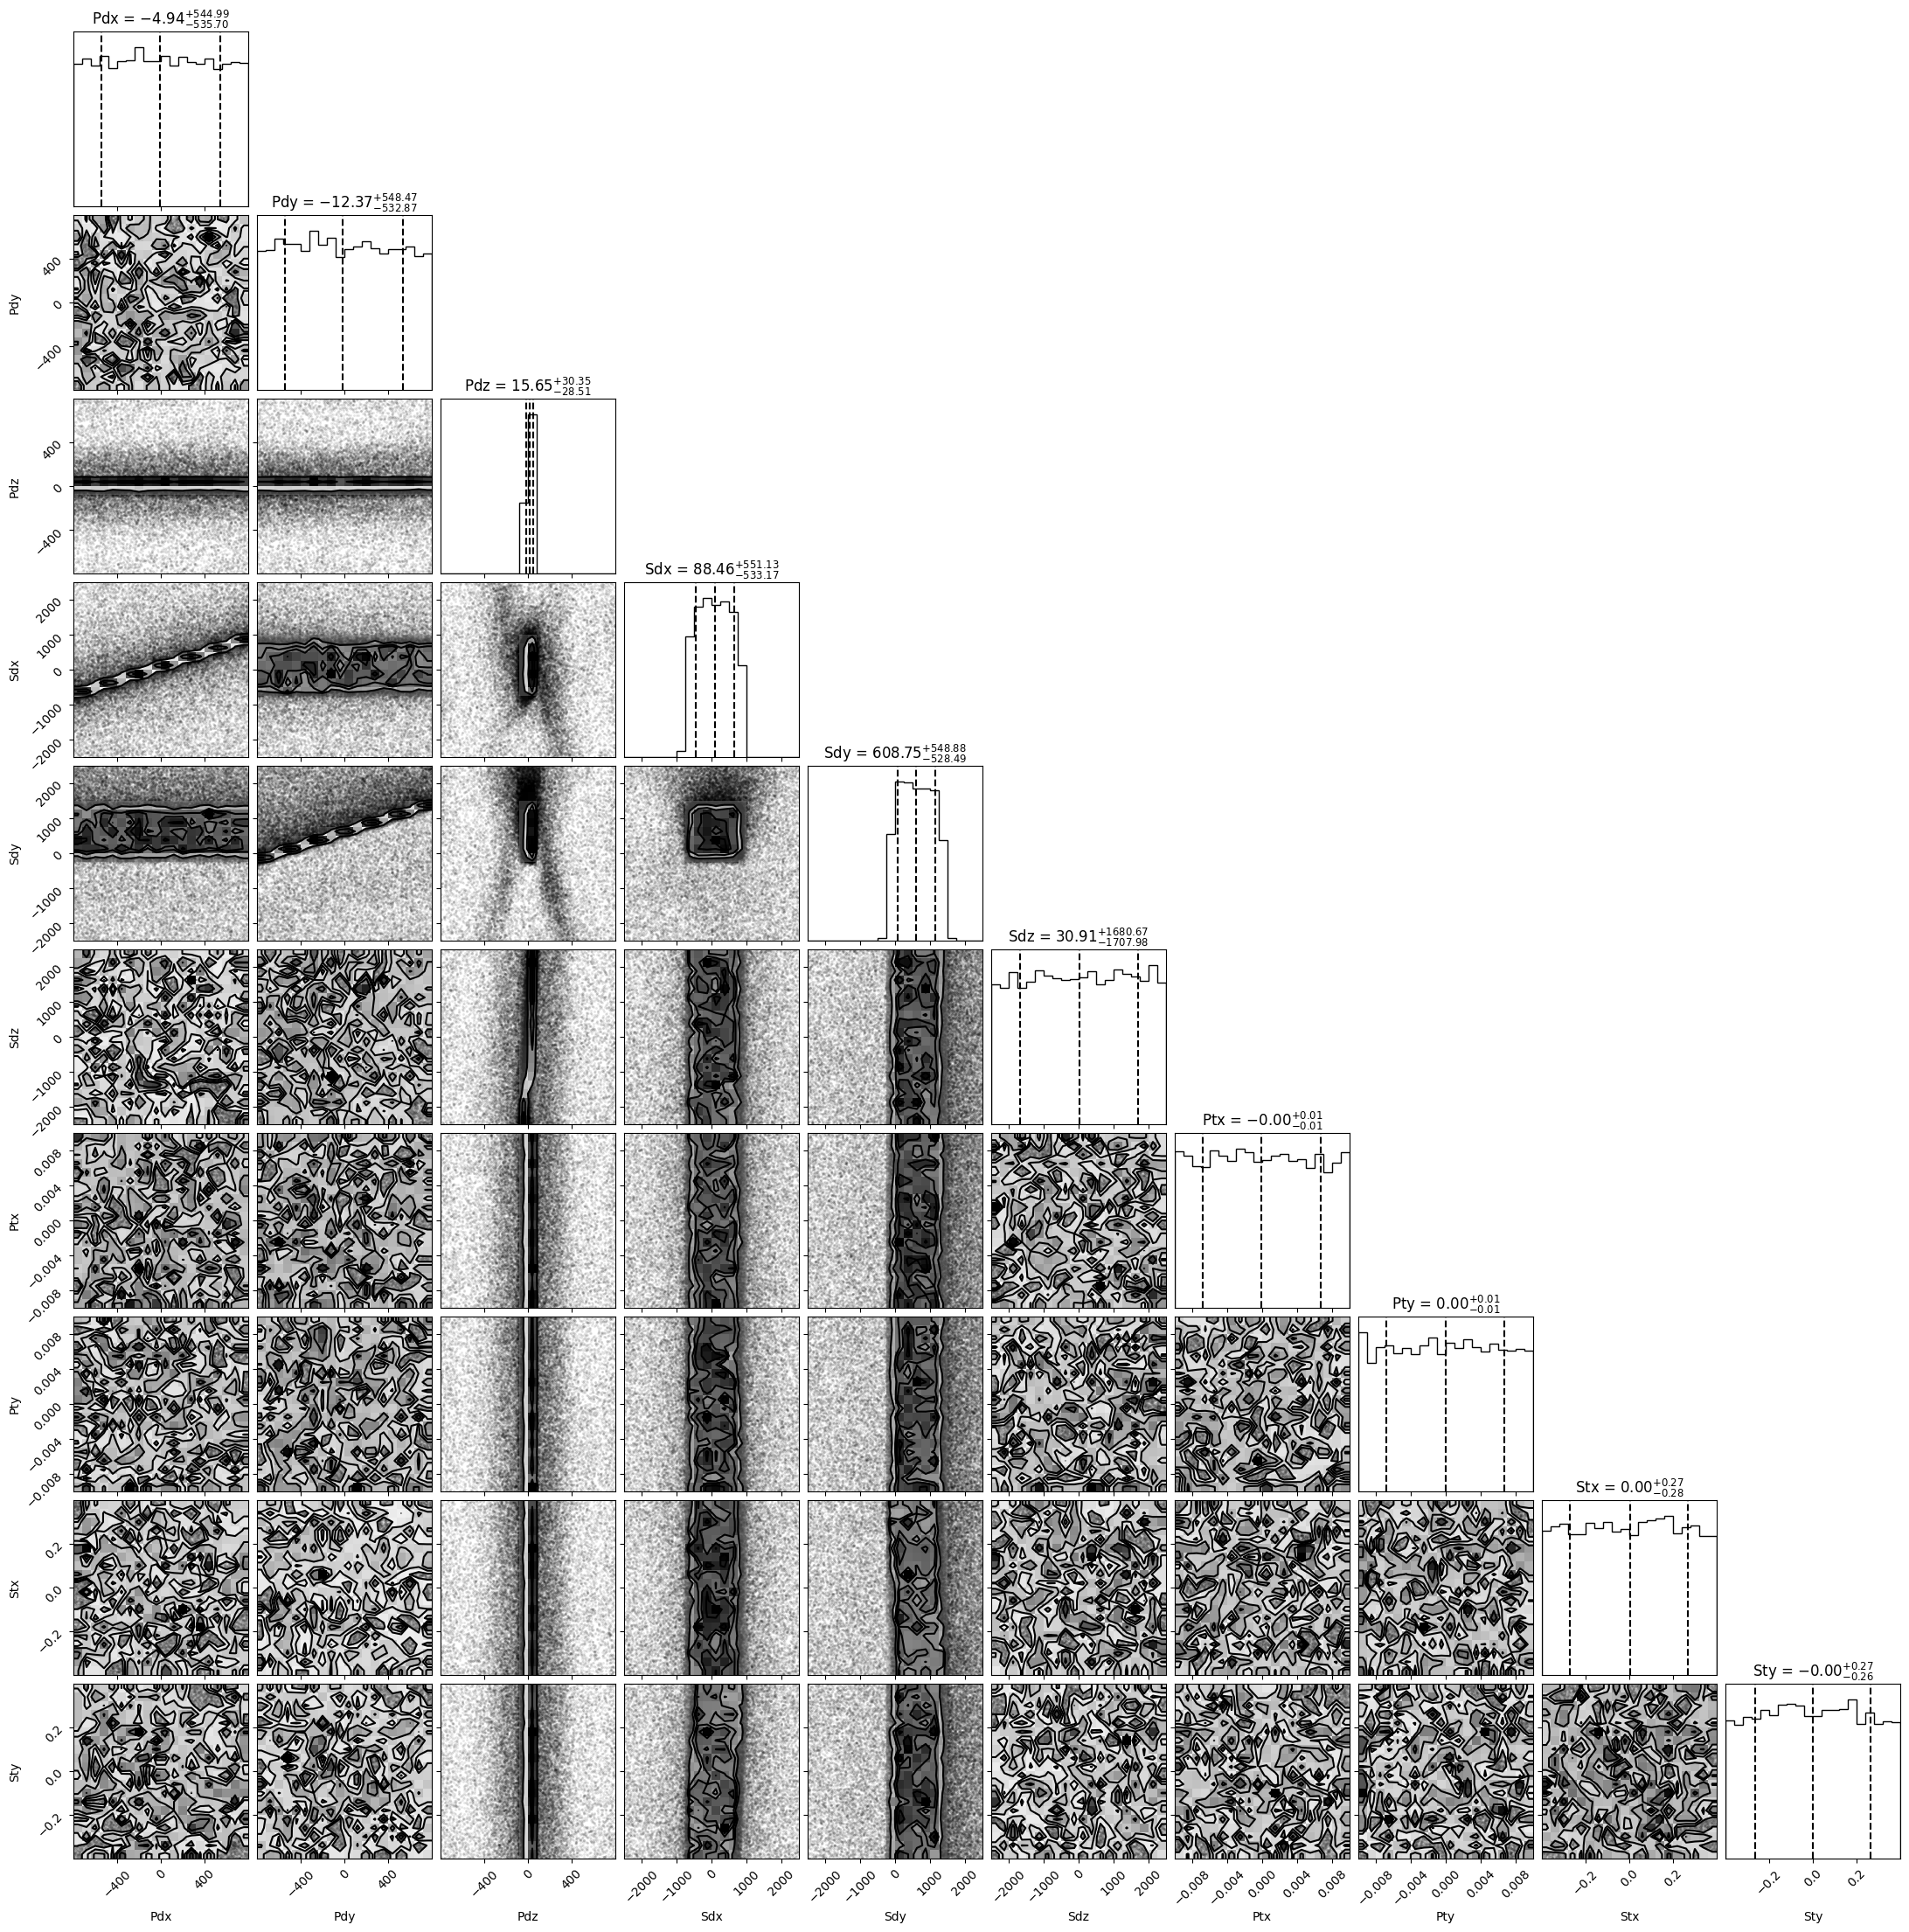

In [145]:
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points, weights=np.exp(log_w), labels=['Pdx', 'Pdy', 'Pdz', 'Sdx', 'Sdy', 'Sdz', 'Ptx', 'Pty', 'Stx', 'Sty'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,)

In [146]:
x0 = [(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,4], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,5], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,6], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,7], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,8], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,9], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

In [147]:
print(x0)

[(array(-59.48061406), array(54.70208565), array(25.35830875), array(87.9049834), array(658.38805454), array(-120.6623582), array(0.00095669), array(-0.00102789), array(-0.0176138), array(-0.04245406))]


In [148]:
print(f"{pdx_true},\n {pdy_true}, \n {pdz_true},\n {sdx_true},\n {sdy_true}, \n {sdz_true}, \n {ptx_true},\n {pty_true},\n {stx_true},\n {sty_true}")

-152.75016400314658,
 316.9119521175452, 
 26.63305492799793,
 -42.31026973120823,
 923.3301076415017, 
 -32.7503419412196, 
 2.9825886165449316e-05,
 1.6083989287690292e-05,
 0.02694973236912114,
 0.009802980828159563


In [149]:
bounds = [(np.quantile(points[-100:,0], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,0], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,1], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,1], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,2], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,2], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,3], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,3], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,4], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,4], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,5], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,5], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,6], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,6], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,7], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,7], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,8], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,8], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,9], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,9], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

In [150]:
bounds

[(array(-788.05552593), array(782.40001922)),
 (array(-613.20426477), array(776.68353112)),
 (array(-7.37370513), array(63.80425417)),
 (array(-655.3227307), array(860.30870401)),
 (array(-44.25817821), array(1433.66628259)),
 (array(-2229.00147125), array(2418.72956479)),
 (array(-0.00919593), array(0.00960329)),
 (array(-0.00915327), array(0.0096127)),
 (array(-0.35767556), array(0.36295057)),
 (array(-0.30603771), array(0.30265517))]

In [21]:
bounds = [(-800, 800), (-800, 800), (-800, 800), (-2500, 2500), (-2500, 2500), (-2500, 2500), (-0.01, 0.01), (-0.01, 0.01), (-0.4, 0.4), (-0.4, 0.4)]

In [39]:
def my_callback(xk, convergence=None):
    # differential_evolution: (best_x, convergence_metric)
    # minimize: single OptimizeResult (legacy)
    if convergence is not None:
        fun = float(lstep(xk))
        with open("solutions_logn.txt", "a") as f:
            f.write(f"Objective: {fun}, Best X: {xk}\n")
        if fun <= 1e-15:
            print(f"Terminating: reached objective value {fun}")
            return True
        return False
    with open("solutions_logn.txt", "a") as f:
        f.write(f"Objective: {xk.fun}, Best X: {xk.x}\n")
    if xk.fun <= 1e-15:
        print(f"Terminating: reached objective value {xk.fun}")
        return True
    return False

In [76]:
ct = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15)
ctf10 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(1,0))
ctf01 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(0,1))
ctf11 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(1,1))
ctfm10 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(-1,0))
ctf0m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(0,-1))
ctfm11 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(-1,1))
ctf1m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(1,-1))
ctfm1m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(-1,-1))
ctf05 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=15, field=(0.5, 0.5))

In [19]:
def lstep(t):
      return np.sum(np.array(ct - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11))**2 + np.array(ctf10 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(1,0)))**2 + np.array(ctf01 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(0,1)))**2 + np.array(ctf11 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(1,1)))**2 + np.array(ctfm10 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(-1,0)))**2 + np.array(ctf0m1 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(0,-1)))**2 + np.array(ctfm11 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(-1,1)))**2 + np.array(ctf1m1 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(1,-1)))**2 + np.array(ctfm1m1 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(-1,-1)))**2 + np.array(ctf05 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(0.5,0.5)))**2)
#result = differential_evolution(lstep, bounds, callback = my_callback, x0=x0, tol=1e-10)
#print(pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true)
#print(result.x)

In [13]:
from optiland.analysis import RmsSpotSizeVsField

(<Figure size 700x450 with 1 Axes>,
 <Axes: xlabel='Normalized Y Field Coordinate', ylabel='RMS Spot Size (mm)'>)

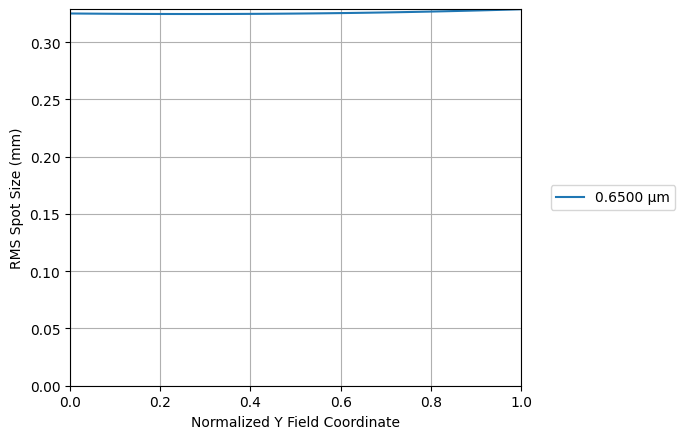

In [16]:
rms_vs_field = RmsSpotSizeVsField(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]))
rms_vs_field.view()

np.float64(4.249425047119365)

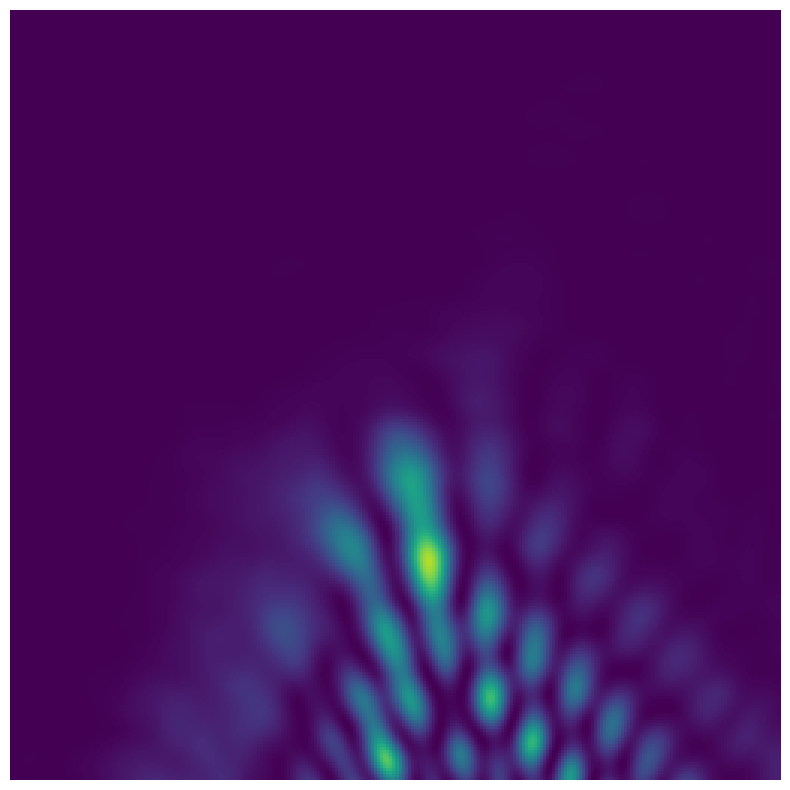

In [15]:
c = [0,0,0,0,0,0,0,0,0,0]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=1)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

(<Figure size 700x450 with 1 Axes>,
 <Axes: xlabel='Normalized Y Field Coordinate', ylabel='RMS Spot Size (mm)'>)

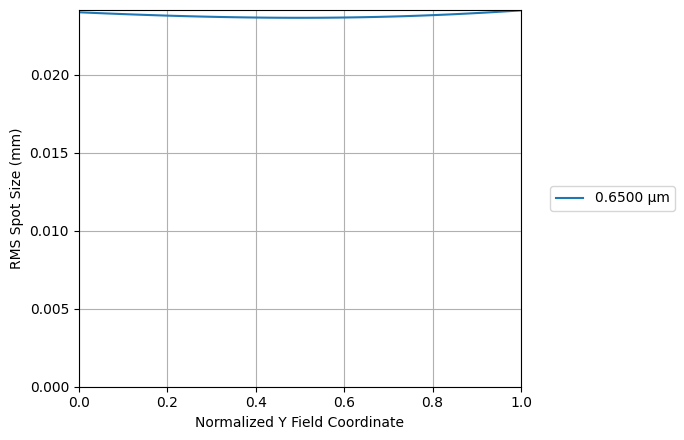

In [20]:
rms_vs_field = RmsSpotSizeVsField(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]))
rms_vs_field.view()

np.float64(0.0019520507126274673)

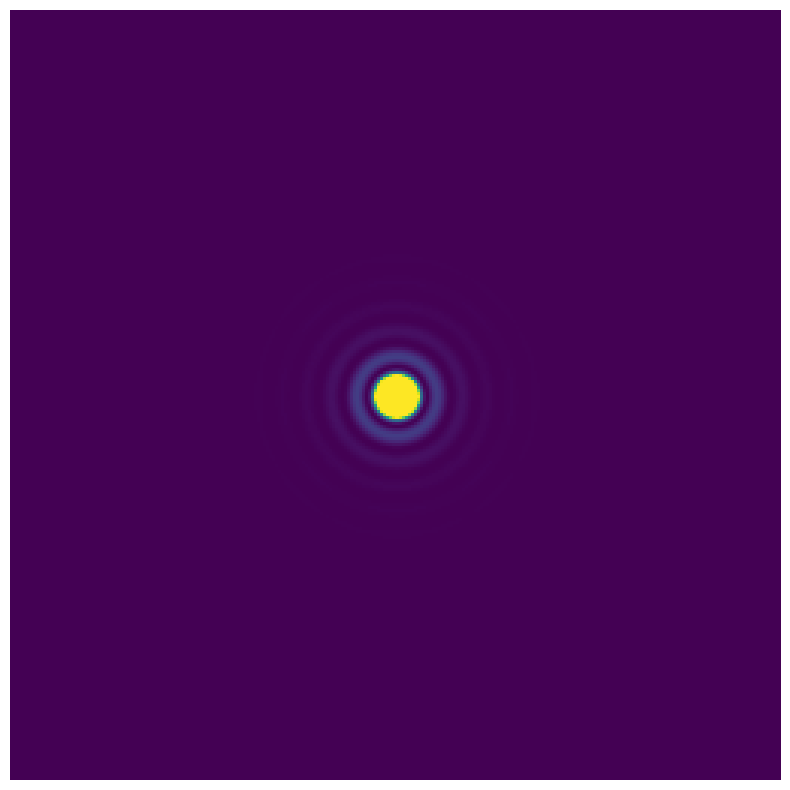

In [15]:
c = [-1.53485600e+02, 3.02265820e+02, 2.47802756e+01, -6.30275771e+01, 9.04780936e+02, -1.53262262e+02, -2.84360586e-03, 9.26637345e-03, 1.50037278e-02, 1.43177187e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.1763997469672051)

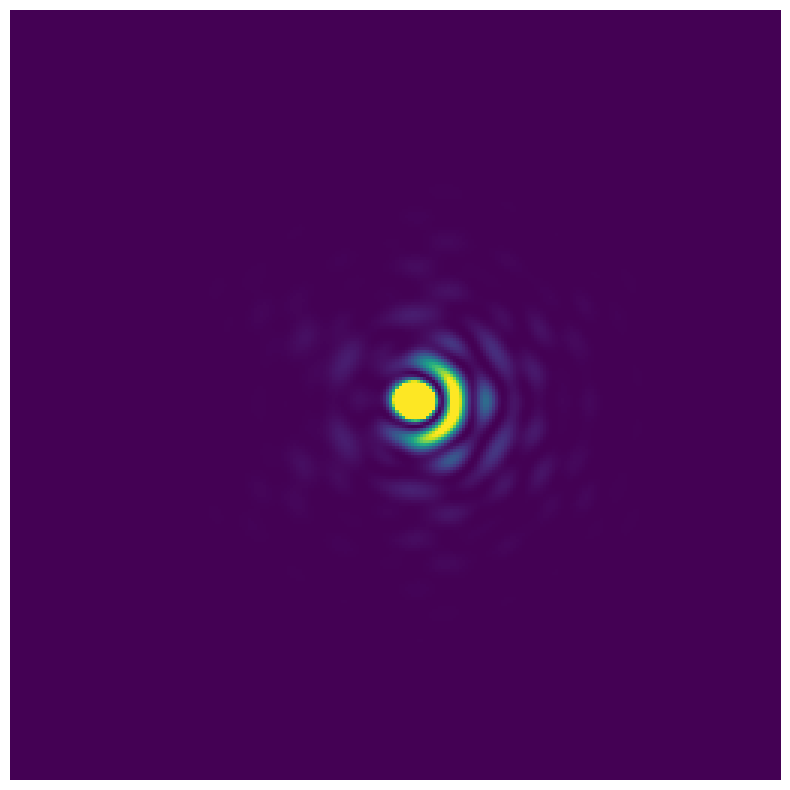

In [182]:
c = [-6.46166171e+02, -6.80473745e+01, 1.15504332e+01, -5.83491005e+02, 5.22262666e+02, -9.99922085e+02, -2.07288798e-03, -3.30909888e-03, 4.50396969e-02, -1.18204916e-01]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.08815661284194293)

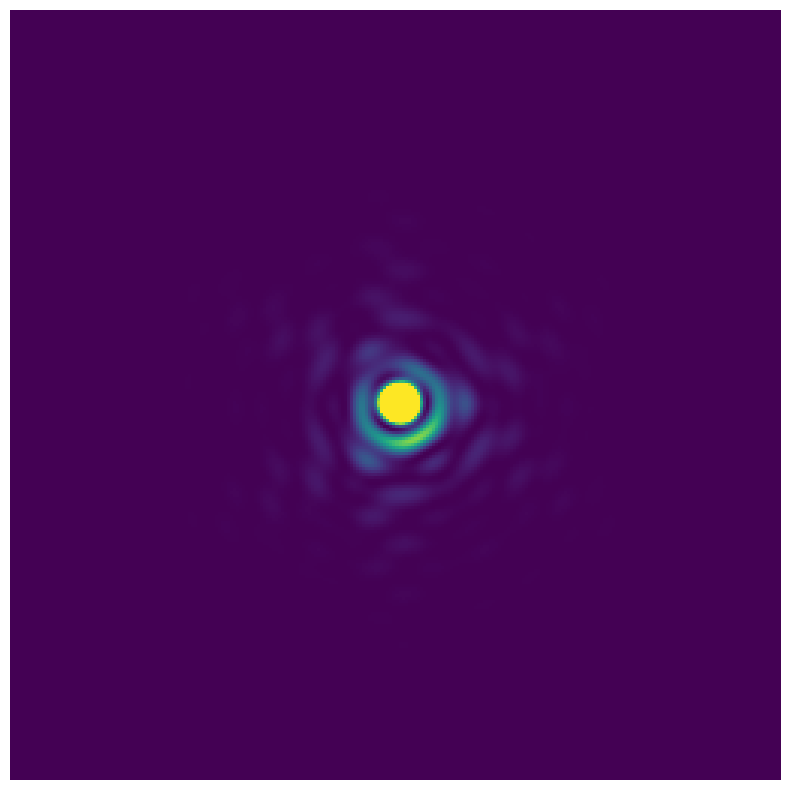

In [183]:
c = [5.15974211e+02, -4.97482513e+02, 8.86543539e+00, 5.58187991e+02, 1.27736188e+02, -1.27726378e+03, 4.45139633e-03, 4.39461902e-03, -7.44757009e-02, -2.53347286e-01]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.03954899404266935)

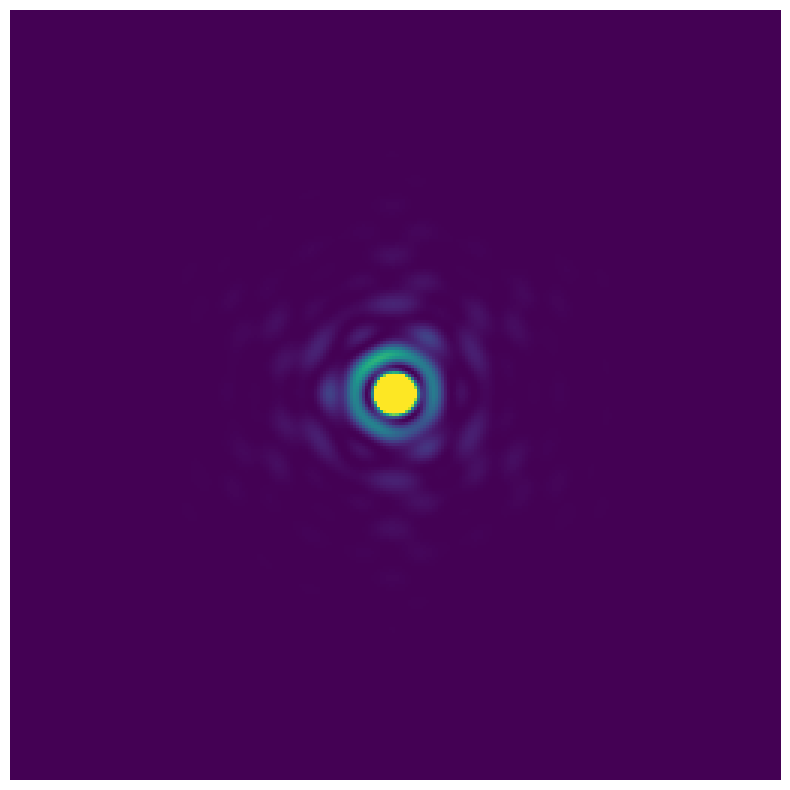

In [184]:
c = [2.70710077e+02, -5.83261193e+01, 3.57215215e+01, 3.39955365e+02, 6.08760313e+02, 5.95178251e+02, 5.45239242e-03, 3.97565703e-03, -1.84966817e-01, -1.59490807e-01]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.021084170578274136)

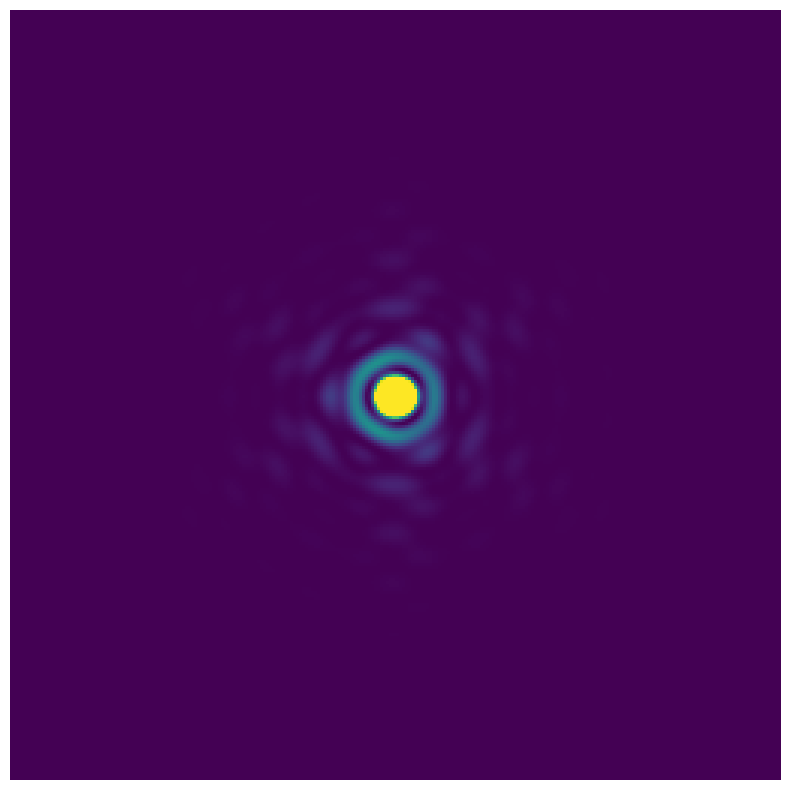

In [185]:
c = [-9.60982819e+01, -1.67262156e+01, 5.48195323e+01, 5.40854177e-02, 6.18159521e+02, 1.79845845e+03, 7.97418699e-03, 7.87416783e-03, -2.77159865e-02, 1.66755747e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

(<Figure size 700x450 with 1 Axes>,
 <Axes: xlabel='Normalized Y Field Coordinate', ylabel='RMS Spot Size (mm)'>)

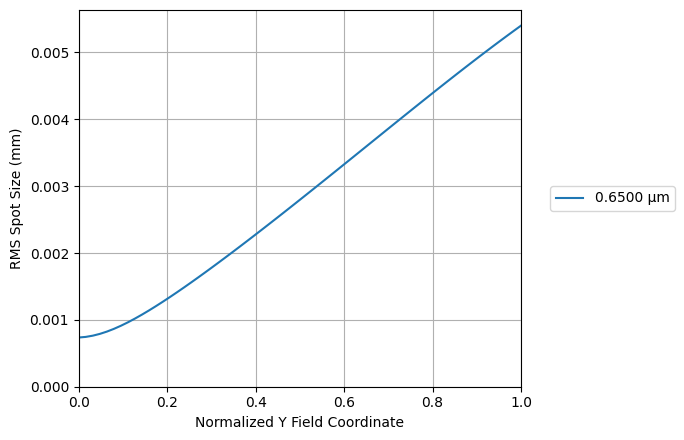

In [22]:
rms_vs_field = RmsSpotSizeVsField(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]))
rms_vs_field.view()

np.float64(0.0014528809851290473)

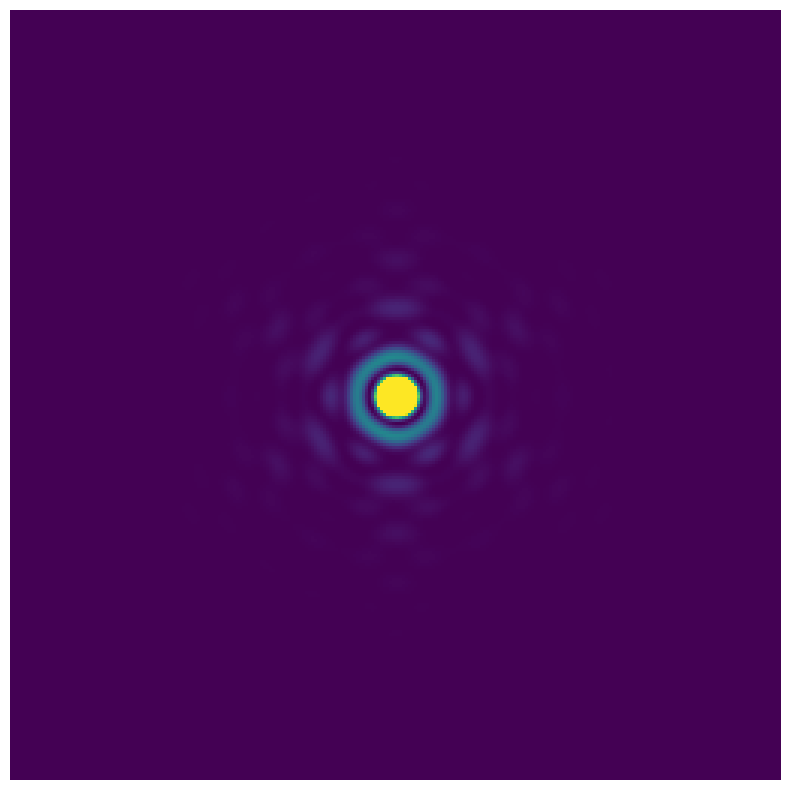

In [21]:
c = [-1.53485600e+02, 3.02265820e+02, 2.47802756e+01, -6.30275771e+01, 9.04780936e+02, -1.53262262e+02, -2.84360586e-03, 9.26637345e-03, 1.50037278e-02, 1.43177187e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.0013799176788977425)

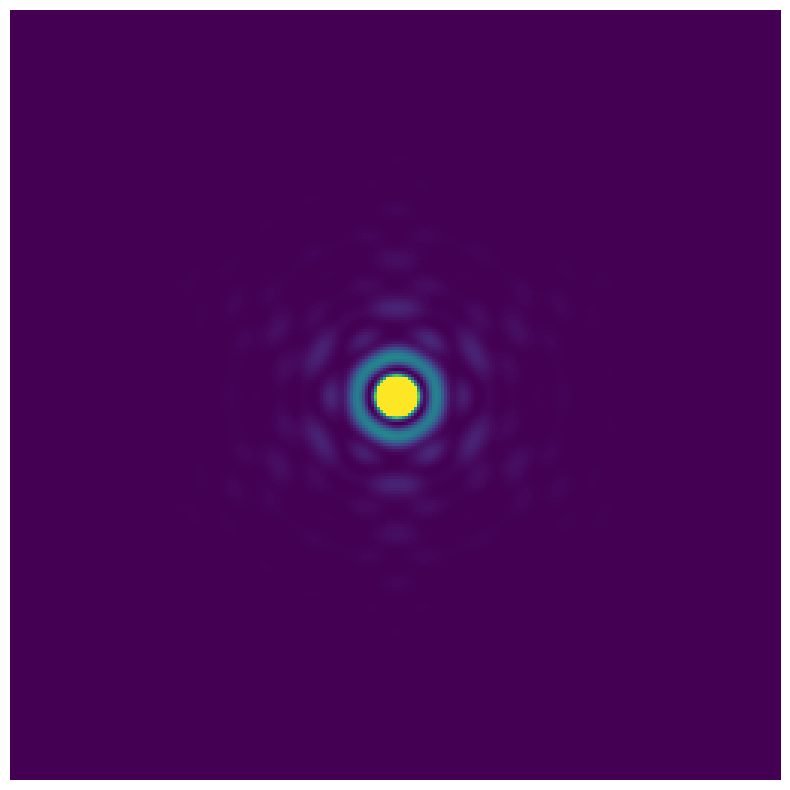

In [35]:
c = [-1.54857144e+02, 3.05542159e+02, 2.43779043e+01, -6.45113602e+01, 9.06428999e+02, -1.79067257e+02, -2.64823506e-03, 9.99261984e-03, 2.44098564e-02, 2.15194286e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.023 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

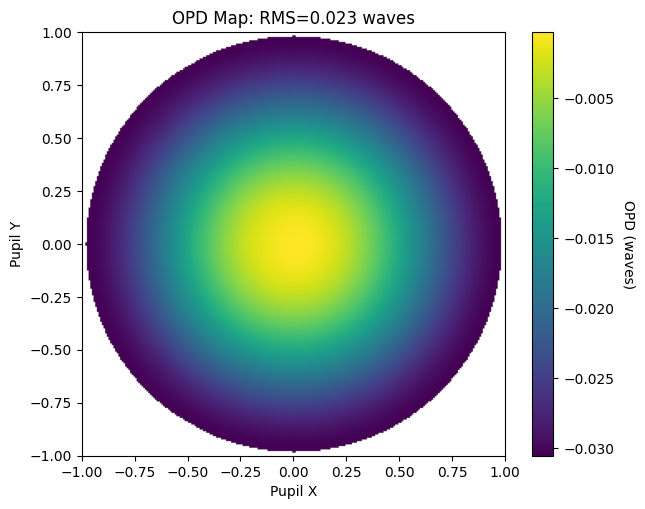

In [148]:
c = [0,0,0,0,0,2,0,0,0,0]
OPD(telescopeCreation(pdx=c[0], pdy=c[1], pdz=c[2], sdx=c[3], sdy=c[4], sdz=c[5], ptx=c[6], pty=c[7], stx=c[8], sty=c[9]), field=(0, 0), wavelength=0.65, num_rays=64).view()

In [21]:
lls = []
for i in range(-800, 800, 10):
    ll = loglike([-1.54857144e+02, 3.05542159e+02, 2.43779043e+01, -6.45113602e+01, 9.06428999e+02, -1.79067257e+02, -2.64823506e-03, 9.99261984e-03, 2.44098564e-02, 2.15194286e-02])
    lls.append(ll)

In [22]:
np.arange(-30, 30, 1)[np.argmax(lls)]

np.int64(24)

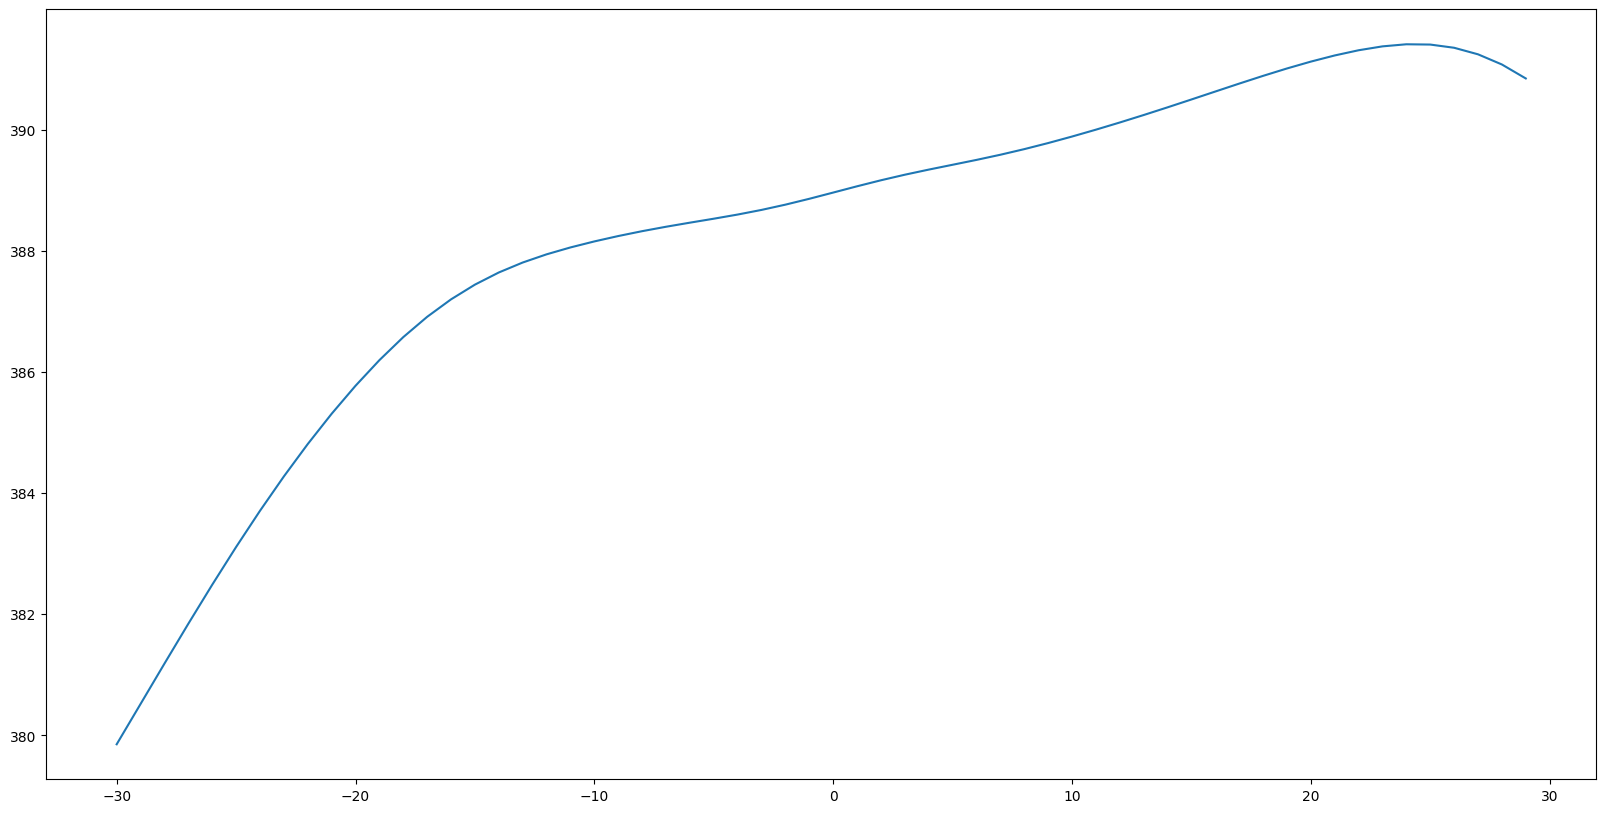

In [23]:
plt.plot(np.arange(-30, 30, 1), lls)

In [ ]:
pdx_true-c[0], pdy_true-c[1], pdz_true-c[2], sdx_true-c[3], sdy_true-c[4], sdz_true-c[5], ptx_true-c[6], pty_true-c[7], stx_true-c[8], sty_true-c[9]

(np.float64(0.7354359968534254),
 np.float64(14.646132117545164),
 np.float64(1.8527793279979292),
 np.float64(20.717307368791772),
 np.float64(18.549171641501744),
 np.float64(120.51192005878039),
 np.float64(0.0028734317461654494),
 np.float64(-0.00925028946071231),
 np.float64(0.01194600456912114),
 np.float64(-0.004514737871840438))

In [36]:
pdx_true-c[0], pdy_true-c[1], pdz_true-c[2], sdx_true-c[3], sdy_true-c[4], sdz_true-c[5], ptx_true-c[6], pty_true-c[7], stx_true-c[8], sty_true-c[9]

(2.1069799968534255,
 11.369793117545157,
 2.255150627997928,
 22.20109046879177,
 16.901108641501764,
 146.3169150587804,
 0.0026780609461654493,
 -0.00997653585071231,
 0.0025398759691211414,
 -0.011716447771840438)

In [1]:
import pandas as pd

In [2]:
import io

with open('solutions_logp.txt', 'r') as f:
    lines = f.read().splitlines()

# Join every three lines together with a comma
processed_data = []
for i in range(0, len(lines), 3):
    processed_data.append(" ".join(lines[i:i+3]))

In [3]:
output_string = "\n".join(processed_data)

with open('cleaned_data.txt', 'w') as f:
    f.write(output_string)

In [15]:
df = pd.read_csv('cleaned_data.txt', header=None, sep=r'\s+', on_bad_lines='skip')

In [16]:
df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,Objective:,"0.0007660020689049385,",Best,X:,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
1,Objective:,"0.0007660020689049385,",Best,X:,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
2,Objective:,"0.0007660020689049385,",Best,X:,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
3,Objective:,"0.0007660020689049385,",Best,X:,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
4,Objective:,"0.0005348000827842976,",Best,X:,-394.937774,-1.265393,25.072832,-288.241144,597.546442,-684.793733,0.000630,-0.001573,0.011290,-8.05919563e-02]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Objective:,"2.530293393843023e-07,",Best,X:,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]
996,Objective:,"2.530293393843023e-07,",Best,X:,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]
997,Objective:,"2.530293393843023e-07,",Best,X:,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]
998,Objective:,"2.530293393843023e-07,",Best,X:,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]


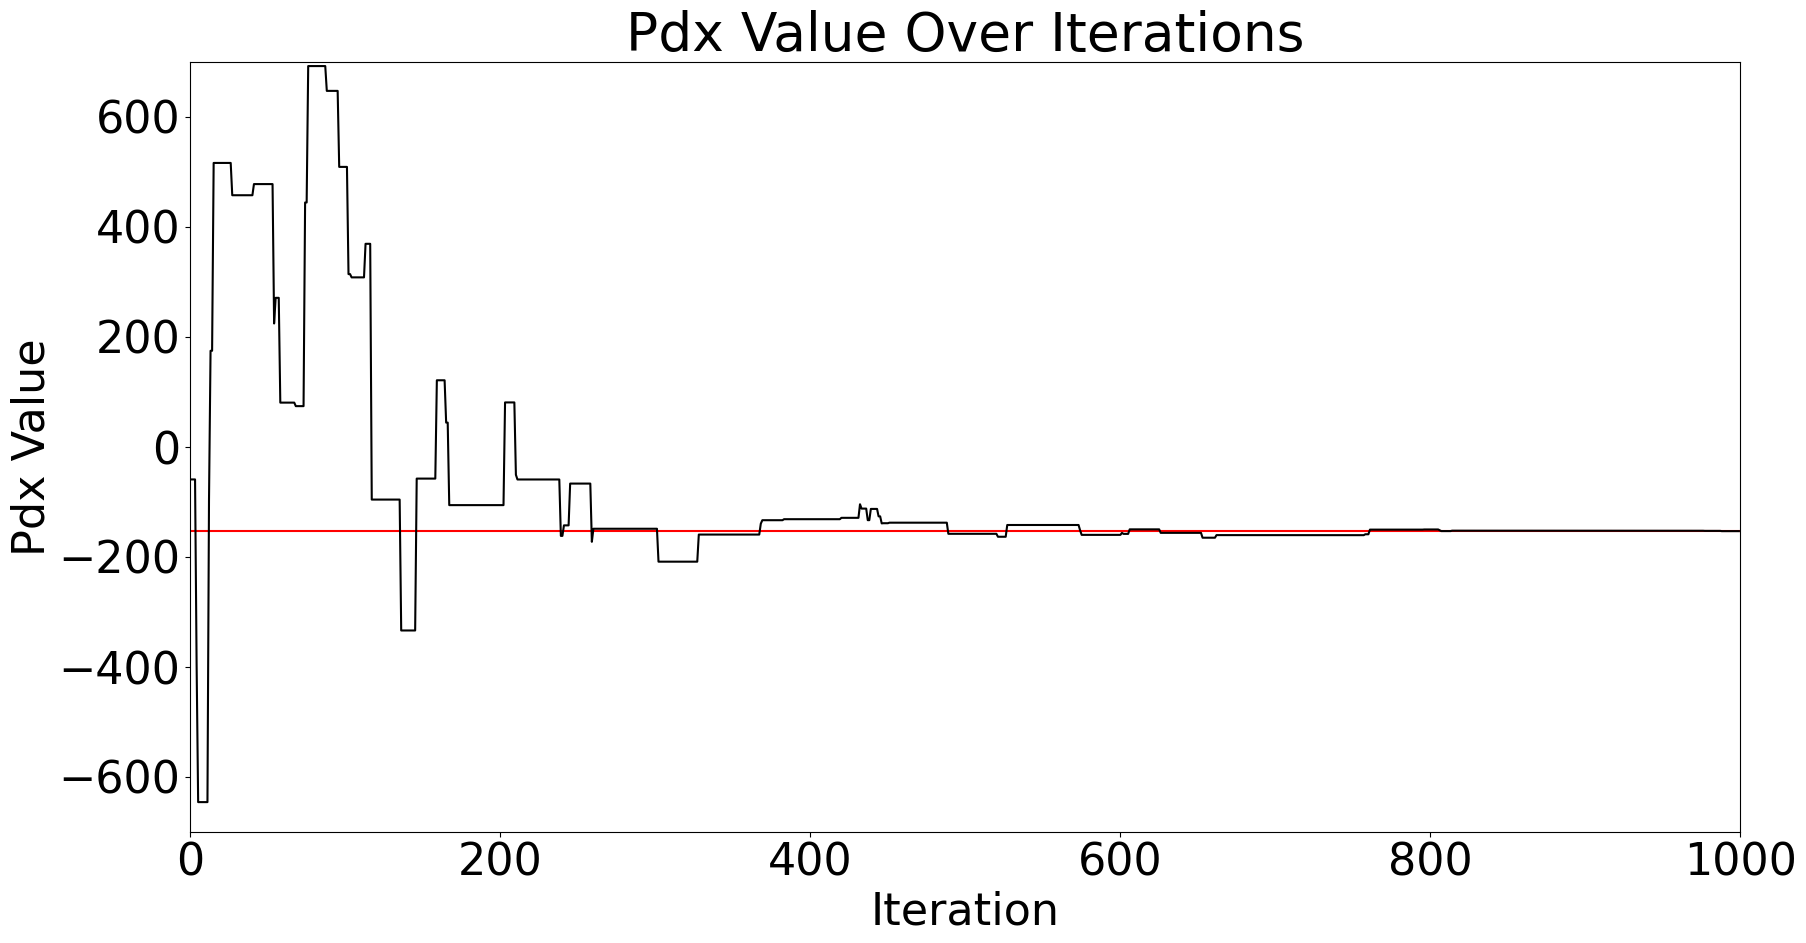

In [18]:
plt.axhline(y=-152.75016400314658, color='r')
plt.plot(df[4], color='k')
#plt.plot(3, -2000)
plt.xlim(0,1000)
plt.ylim(-700,700)
plt.title('Pdx Value Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Pdx Value')
plt.rcParams.update({'font.size': 32}) 

In [1]:
from optiland.fileio import load_zemax_file

In [2]:
tel = load_zemax_file("pearl.zmx")

In [4]:
from optiland.prescription import Prescription
from optiland.prescription import (
    SurfaceGeometryTableSection,
)

# Minimal prescription: overview + first-order only
p_minimal = Prescription(
    tel,
    sections=[SurfaceGeometryTableSection()],
)
p_minimal.view()

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Optical Prescription — Unnamed System                                                                           │
╰──────────────────────────────────────── Generated: 2026-06-12 23:56 UTC ────────────────────────────────────────╯

───────────────────────────────────────────── Surface Data — Geometry ─────────────────────────────────────────────

 S#   Type       Radius (mm)   Thickness (mm)   Conic     Stop   Comment  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0    Plane      ∞             ∞                —                         
  1    standard   -16256.0000   -7400.0050       -0.9954   ✓               
  2    standard   -1660.5750    7449.9700        -1.5665                   
  3    standard   -1830.5174    -1033.6200       -0.7181                   
  4    standard   ∞             1220.3400        —                         
  5    standard   ∞             0.0000           —                        

(<Figure size 700x550 with 2 Axes>,
 <Axes: title={'center': 'OPD Map: RMS=0.025 waves'}, xlabel='Pupil X', ylabel='Pupil Y'>)

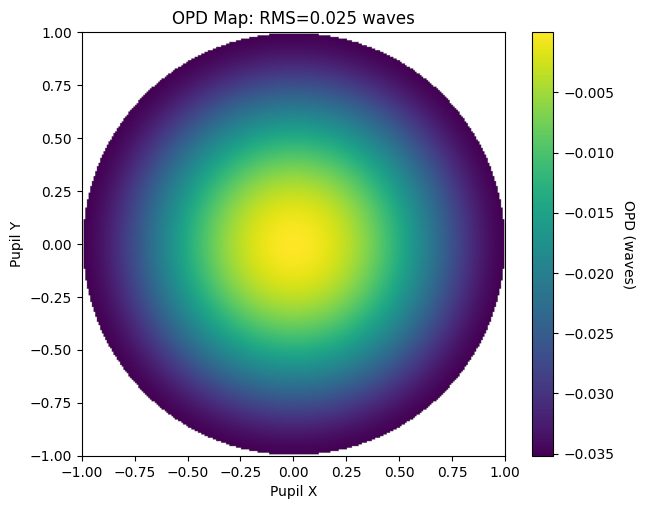

In [78]:
OPD(tel, field=(0, 0), wavelength=0.65).view()

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

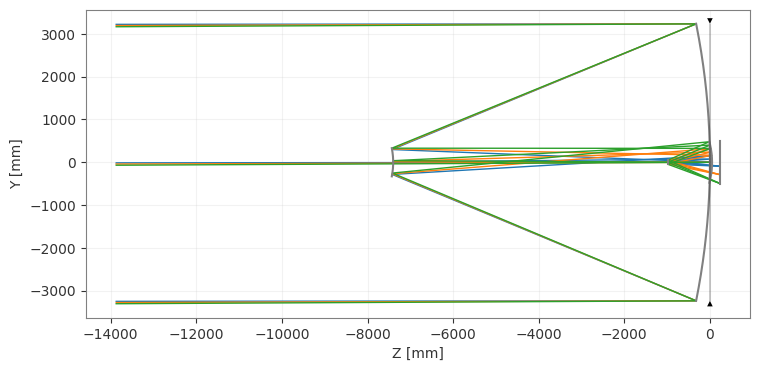

In [74]:
tel.draw()